# Predicting how temperature shifts code ideas (claim L, iteration 8): CPU demo

**Question.** Is sampling temperature a "creativity knob" for *which algorithm* a language model writes? If it changes the algorithm at all, can a handful of tokens predict that change *in advance*?

**What the artifact did** (`method.py`, 15 stages, about 5 GPU-hours on one RTX A4500):

1. **Units.** Each unit is one coding task on one model:
   - Qwen3-8B: A3 trapped rain water, B6 valid anagram, B3 minimum spanning tree weight. These were used to develop the law.
   - Held out: gemma-3-4b-it T04 substring search and R6 first/last position, and Llama-3.1-8B-Instruct T1 grid path.

   For each unit the pipeline **finds the decision token(s) blind**: the one or two generated tokens after which the algorithm is fixed. For example, in B3 `' Kr'` leads to Kruskal and `' Prim'` to Prim, at generated token 61.
2. **Prediction, committed before any temperature sample.** Before sampling at any temperature, the pipeline **hash-commits** (sha256 chain) the law's prediction of the algorithm distribution at T 0.3 / 0.7 / 1.0 / 1.3:

   $$P_T(A) = \sum_c w_T(O_c)\Big[\sum_t \pi_T(t\mid O_c)\,G_T(t,A) + r_T(c)\,\hat P(A\mid \text{resid}_c)\Big] + \Big(1-\sum_c w_T(O_c)\Big)\,q_{rest}(A)$$

   - $\pi_T$ is the tempered next-token distribution at the decision position.
   - $w_T(O_c)$ is the tempered probability of generating the opening $O_c$.
   - $G_T(t,A)=\hat P(A\mid t)$ is measured from T-1 continuations. When a second decision follows $t$, $G_T$ is the same mixture taken over the second token.

   Four rivals are committed as well:
   - **B0**: the fit twin's shares at every T (temperature has no effect).
   - **B1**: algorithm-level tempering, $q^{1/T}$.
   - **B2**: the law with a single decision only.
   - **BH**: the same law at the highest-entropy position.
3. **Scoring.** The pipeline samples the **same 100 random streams at every temperature**. The score is MAE: the mean over T of the total-variation distance between the predicted and observed label distributions. A unit passes at MAE ≤ 0.10 with H(algorithm | decision classes) ≤ 0.3 bits.

**Result: claim L is PARTIAL.**
- 5 of 6 units pass: A3 0.029, B6 0.054, B3 0.043, G-T04 0.033, G-R6 0.014. L-T1 fails at 0.142.
- Only 3 held-out units were scored, below the 4 the protocol requires.
- Temperature never added an algorithm. It re-weighted the 2-3 algorithms the model already uses, through one or two tokens.

**What this notebook runs (CPU only, a few minutes).** Colab cannot run the GPU stages (model loading, blind locator, teacher forcing, the 4,800-program sweep) or the LLM judges. Their outputs are loaded from `mini_demo_data.json`, one record per scored unit. Everything after them is re-run here with the artifact's own code:
- the law's CPU unit tests (U5, U8-U11);
- **the law itself**: every committed prediction (L, B2, BH, B0, B1), recomputed from the committed teacher-forced decision-token probabilities;
- the sha256 **hash chain** of all 13 commitments, with each committed file rebuilt byte for byte;
- the committed **scoring** (`src/analysis_L.py`): MAEs, McNemar drops, replay accuracy, H, bootstrap CIs, placebos, phrasing clusters and the verdict;
- the standard-library **re-derivation** (`audit/rederive.py`, `audit/sign_test.py`);
- the **base-vs-instruct** decision margins (`src/base_arm.py`);
- the figures **F1-F6** (`src/figures8.py`).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (the committed scoring code logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, pandas, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- original imports: method.py, src/analysis_L.py, src/predict8.py, src/figures8.py, audit/rederive.py ---
import ast
import hashlib
import itertools
import json
import math
import os
import random
import subprocess
import sys
from collections import Counter
from pathlib import Path
from typing import Any

import numpy as np
from loguru import logger
from scipy.stats import binomtest, fisher_exact

import matplotlib
import matplotlib.pyplot as plt   # figures8.py also calls matplotlib.use("Agg"); omitted so figures show inline

# --- notebook-only additions ---
import re                         # src/opening_cls.py (code_part)
import time
import pandas as pd               # result tables
from IPython.display import display

# src/cfg8.py setup_logging(): loguru to stdout (the rotating log-file sink is omitted)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")

# the law's three modules are written here verbatim by the %%writefile cells of section 2, then imported
Path("demo_src").mkdir(exist_ok=True)
sys.path.insert(0, str(Path("demo_src").resolve()))
sys.dont_write_bytecode = True    # no __pycache__/ next to them
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 200)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-43/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
if not {"units", "commits", "base_arm", "reference"} <= set(data):
    # an older demo file (or a cached copy) is still served at GITHUB_DATA_URL: use the local mini_demo_data.json
    print("the file at GITHUB_DATA_URL has an older layout; using the local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())

# Top-k-10 programs that are token-identical to their top-p-1 twin (same slot, same uniforms) were stored without
# their text to keep the file small; restore it so every row looks like a row of data/samples_raw.jsonl.
for U in data["units"].values():
    twin = {(r["template"], r["slot"], r["T"]): r for r in U["rows"] if r["arm"] == "sweep"}
    for r in U["rows"]:
        if r.get("text_from_sweep_twin"):
            r["text"] = twin[(r["template"], r["slot"], r["T"])]["text"]

md = data["metadata"]
print(md["title"])
print(md["description"])
print(f"units: {md['units']}   program rows: {md['n_rows']}   commits: {len(data['commits']['log'])}")
print("rows per unit:", {u: len(U["rows"]) for u, U in data["units"].items()})

the file at GITHUB_DATA_URL has an older layout; using the local mini_demo_data.json
Predicting how temperature shifts code ideas (iteration 8, claim L)
Inputs and outcomes of the six scored units of claim L: blind-located decision tokens and their Phat tables (COMMIT #1), the law's committed predictions and the compact teacher-forced quantities they were computed from (COMMIT #2), and the same-stream temperature sweep (T 0.3/0.7/1.0/1.3 x top-p 1 / top-k 10, 100 slots per cell) with frozen and adjudicated labels.
units: ['A3', 'B6', 'B3', 'G-T04', 'G-R6', 'L-T1']   program rows: 4800   commits: 13
rows per unit: {'A3': 800, 'B6': 800, 'B3': 800, 'G-T04': 800, 'G-R6': 800, 'L-T1': 800}


## Configuration

These are the only knobs; everything else is fixed by the pre-registered protocol (`protocol8L.json`, COMMIT #0).

- `UNITS_TO_RUN` picks which of the six scored units are re-scored.
- The other values are replicate counts for the bootstraps, placebos and unit tests.

With the **original** counts (the values in the comments), the seeded random streams reproduce the committed bootstrap CIs and placebo rates exactly. With smaller counts, only those stochastic numbers change. MAEs, McNemar counts, H and the verdict do not depend on them.

In [5]:
# ---- tunable parameters ----
# These are the artifact's original values: the whole notebook still runs in well under a minute on a CPU
# (the GPU stages are not re-run). For a quick look, reduce them, e.g. UNITS_TO_RUN = ["G-R6"], N_BOOT = 10,
# N_DROP_PLACEBO = 5, N_TOKENMAP_PLACEBO = 5, N_HILL_REP = 5, U10_N = 10, U11_N_U = 100, N_REDERIVE_PLACEBO = 5,
# N_SIGN_PLACEBO = 10 (only the seeded stochastic checks then change).
UNITS_TO_RUN = ["A3", "B6", "B3", "G-T04", "G-R6", "L-T1"]   # the six scored units (original: all six)
N_BOOT = 1000                 # slot-bootstrap replicates of MAE_L - MAE_rival (analysis_L 7.6); original: 1000
N_DROP_PLACEBO = 500          # temperature-label shuffles, drop-test placebo (analysis_L 7.3); original: 500
N_TOKENMAP_PLACEBO = 200      # Phat-row shuffles across decision tokens (analysis_L token_map_placebo); original: 200
N_HILL_REP = 200              # rarefaction replicates of correct-only Hill-1 diversity at depth 25; original: 200
U10_N = 1000                  # synthetic logit sequences in unit test U10 (top-k shadow sampling); original: 1000
U11_N_U = 10000               # Monte-Carlo uniform vectors in unit test U11 (replay walk); original: 10000
N_REDERIVE_PLACEBO = 300      # temperature shuffles in audit/rederive.py placebo 1; original: 300
N_SIGN_PLACEBO = 2000         # random L/B0 swaps in audit/sign_test.py placebo; original: 2000

ORIGINAL_COUNTS = (N_BOOT, N_DROP_PLACEBO, N_TOKENMAP_PLACEBO, N_HILL_REP) == (1000, 500, 200, 200)
T_START = time.time()
print("units:", UNITS_TO_RUN, "| original replicate counts:", ORIGINAL_COUNTS)

units: ['A3', 'B6', 'B3', 'G-T04', 'G-R6', 'L-T1'] | original replicate counts: True


## 0. The pipeline: `method.py`

`method.py` is the artifact's entry point. It is a thin driver: each of its 15 stages runs one or more scripts in `src/` as subprocesses, in a fixed order. Every stage resumes from its result files, and the commit stages refuse to overwrite a commit. The code below is the original apart from `ROOT`.

`main()` is defined but **not called**. Running it needs the full repository, a GPU with at least 20 GB, the four model checkpoints and the judge API keys. Instead, the cells of this notebook re-run the CPU stages in-process on `mini_demo_data.json`. The printout maps each stage to where this notebook handles it.

In [6]:
# ===== method.py =====
"""Predicting how temperature shifts code ideas (iteration 8, claim L): entry point.

Runs every stage in order (each stage resumes from its result files; commits refuse to overwrite):
  vendor      copy the prior artifacts' files into inputs/ with sha256 (src/vendor_inputs.py)
  prompts     prompt ids per (unit, template) with source checks (src/prompts8.py)
  cputests    U5/U8/U9/U10/U11, change-point rule, scoring dry run on iteration-7 data, labeller references
  commit0     protocol8L.json + code hashes, COMMIT #0 (src/commit0.py)
  gemma       held-out family 1: tests, fit (+ engine check), locate, COMMIT #1, predict, COMMIT #2, sweep
  llama       held-out family 2: the same plus bench-candidate selection (COMMIT #1a) and label re-gate (COMMIT #1b)
  qwen        law-development family: A3, B6 (second decisions), B3 (fresh streams)
  base        base sub-arm: Qwen3-8B and Qwen3-8B-Base teacher forcing, then analysis (src/base_arm.py)
  adjudicate  judges on cells with > 20% 'other' (src/novelty8.py adjudicate)
  analysis    committed scoring (src/analysis_L.py) -> results/analysis_L.json, results/verdict.json
  novelty     novelty audit of every correct off-catalogue program (src/novelty8.py audit)
  figures     F1-F6 (src/figures8.py)
  report      results/summary.md (src/report8.py)
  outputs     method_out.json (src/outputs8.py)
  rederive    audit/rederive.py (standard library only)
Usage: .venv/bin/python method.py all | <stage>[,<stage>...]
"""

ROOT = Path.cwd()             # original: Path(__file__).resolve().parent
SRC = ROOT / "src"
PY = sys.executable
GPU_STAGES = "tests,fit,locate,commit1,predict,commit2,sweep"

STAGES = {
    "vendor": [[PY, "vendor_inputs.py"]],
    "prompts": [[PY, "prompts8.py"]],
    "cputests": [[PY, "tests_cpu.py"]],
    "commit0": [[PY, "commit0.py"]],
    "gemma": [[PY, "gpu8.py", "gemma", GPU_STAGES]],
    "llama": [[PY, "gpu8.py", "llama", GPU_STAGES]],
    "qwen": [[PY, "gpu8.py", "qwen", GPU_STAGES]],
    "base": [[PY, "base_arm.py", "gpu", "qwen"], [PY, "base_arm.py", "gpu", "qwen_base"], [PY, "base_arm.py", "analyze"]],
    "adjudicate": [[PY, "novelty8.py", "adjudicate"]],
    "analysis": [[PY, "analysis_L.py"]],
    "novelty": [[PY, "novelty8.py", "audit"]],
    "figures": [[PY, "figures8.py"]],
    "report": [[PY, "report8.py"]],
    "outputs": [[PY, "outputs8.py"]],
    "rederive": [[PY, "-I", str(ROOT / "audit" / "rederive.py")]],
}
ORDER = list(STAGES)


def main() -> None:
    want = ORDER if len(sys.argv) < 2 or sys.argv[1] == "all" else sys.argv[1].split(",")
    env = dict(os.environ, PYTORCH_CUDA_ALLOC_CONF="expandable_segments:True")
    for st in want:
        for cmd in STAGES[st]:
            print(f"== {st}: {' '.join(cmd[1:])}", flush=True)
            r = subprocess.run(cmd, cwd=str(SRC), env=env)
            if r.returncode != 0:
                raise SystemExit(f"stage {st} failed ({r.returncode})")


# main() is not called (see the markdown above). Where each stage is handled in this notebook:
IN_THIS_NOTEBOOK = {
    "vendor": "not needed: the inputs the CPU stages read are in mini_demo_data.json",
    "prompts": "loaded: prompt ids are fixed inside the committed payloads",
    "cputests": "RE-RUN: the law's unit tests U5, U8-U11 (section 2)",
    "commit0": "loaded; its hash-chain link is re-verified (section 4)",
    "gemma": "GPU: locator / teacher forcing / sweep loaded; the law's CPU step re-run (section 3)",
    "llama": "GPU: as gemma",
    "qwen": "GPU: as gemma",
    "base": "GPU teacher forcing loaded; decision-position analysis re-run (section 7)",
    "adjudicate": "LLM judges: adjudicated labels loaded and applied (section 5)",
    "analysis": "RE-RUN: the committed scoring src/analysis_L.py (section 5)",
    "novelty": "LLM judges: not re-run (artifact result: 0 novel among 4,703 correct programs)",
    "figures": "RE-RUN: F1-F6 (section 8)",
    "report": "replaced by the tables of section 8",
    "outputs": "not needed",
    "rederive": "RE-RUN: audit/rederive.py + audit/sign_test.py (section 6)",
}
for st in ORDER:
    cmds = " ; ".join(" ".join(c[1:]).replace(str(ROOT) + "/", "") for c in STAGES[st])
    print(f"{st:<11} {cmds:<70} -> {IN_THIS_NOTEBOOK[st]}")

vendor      vendor_inputs.py                                                       -> not needed: the inputs the CPU stages read are in mini_demo_data.json
prompts     prompts8.py                                                            -> loaded: prompt ids are fixed inside the committed payloads
cputests    tests_cpu.py                                                           -> RE-RUN: the law's unit tests U5, U8-U11 (section 2)
commit0     commit0.py                                                             -> loaded; its hash-chain link is re-verified (section 4)
gemma       gpu8.py gemma tests,fit,locate,commit1,predict,commit2,sweep           -> GPU: locator / teacher forcing / sweep loaded; the law's CPU step re-run (section 3)
llama       gpu8.py llama tests,fit,locate,commit1,predict,commit2,sweep           -> GPU: as gemma
qwen        gpu8.py qwen tests,fit,locate,commit1,predict,commit2,sweep            -> GPU: as gemma
base        base_arm.py gpu qwen ; base_arm.py gp

## 1. Constants: `src/cfg8.py`

These are the design constants that the CPU stages read, copied from `src/cfg8.py`:
- the models;
- the five prompt templates W1-W5;
- the units and their algorithm catalogues;
- the four temperatures and the two samplers (`p1` = top-p 1, i.e. the full vocabulary; `k10` = top-k 10);
- the 20 sweep slots per template, which give N = 100 per cell;
- the bootstrap seed;
- the pre-registered thresholds.

Omitted: paths, seed helpers and the GPU-only locator constants. `N_BOOT` is set in the config cell.

All randomness in the artifact is keyed. Each program slot owns one PCG64 uniform stream, and generated step *t* uses the slot's *t*-th uniform. That stream is reused at every temperature and by both samplers (common random numbers). As a result, a slot's program at T 0.3 and at T 1.3 differ *only* because the temperature changed.

In [7]:
# ===== src/cfg8.py (constants used by the CPU stages) =====
FAMILIES: dict[str, dict[str, Any]] = {
    "gemma": {"model_id": "google/gemma-3-4b-it", "rev": "093f9f388b31de276ce2de164bdc2081324b9767",
              "stop_ids": (1, 106), "pad_id": 106},
    "llama": {"model_id": "meta-llama/Llama-3.1-8B-Instruct", "rev": "0e9e39f249a16976918f6564b8830bc894c89659",
              "stop_ids": (128001, 128008, 128009), "pad_id": 128009},
    "qwen": {"model_id": "Qwen/Qwen3-8B", "rev": "b968826d9c46dd6066d109eabc6255188de91218",
             "stop_ids": (151645, 151643), "pad_id": 151645},
    "qwen_base": {"model_id": "Qwen/Qwen3-8B-Base", "rev": "49e3418fbbbca6ecbdf9608b4d22e5a407081db4",
                  "stop_ids": (151645, 151643), "pad_id": 151643},
}
FAMILY_ORDER = ("gemma", "llama", "qwen")          # held-out families first
PRECISION = "bf16"
U_LEN = 2048

# ------------------------------------------------------------------------------------------------ units
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
LLAMA_BENCH_ORDER = ("T03", "T06", "T04", "R1", "T14", "T10", "T08")   # ITER2 exp11 pilot, most mixed first
LLAMA_BENCH_KEEP = 2
LLAMA_MINORITY_BAR = 0.10

UNITS: dict[str, dict[str, Any]] = {
    # law-development units (Qwen3-8B; iteration-7 law units), fit keys = iteration-7 twin keys
    "A3": {"family": "qwen", "task": "A3", "lab": "a", "held_out": False, "max_new": 640, "batch": 20,
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"],
           "name": "trapped rain water", "fence": "bench"},
    "B6": {"family": "qwen", "task": "B6", "lab": "b", "held_out": False, "max_new": 384, "batch": 20,
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array"], "name": "valid anagram",
           "fence": "bench"},
    "B3": {"family": "qwen", "task": "B3", "lab": "b", "held_out": False, "max_new": 768, "batch": 20,
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"], "name": "minimum spanning tree weight",
           "fence": "bench"},
    # held-out units (never used to develop the law or its procedure)
    "G-T04": {"family": "gemma", "task": "T04", "lab": "bench", "held_out": True, "max_new": 1024, "batch": 20,
              "catalogue": ["naive", "kmp", "rabin_karp", "z_algorithm", "bmh", "builtin"],
              "name": "substring search", "fence": "bench"},
    "G-R6": {"family": "gemma", "task": "R6", "lab": "bench", "held_out": True, "max_new": 1024, "batch": 20,
             "catalogue": ["binary_search", "bisect_module", "exponential_search", "linear_scan"],
             "name": "first and last position", "fence": "bench"},
    "L-T1": {"family": "llama", "task": "T1", "lab": "path", "held_out": True, "max_new": 1536, "batch": 10,
             "catalogue": ["bfs", "dfs", "bibfs", "astar_gbfs", "dijkstra", "iddfs"], "name": "grid path",
             "fence": "path"},
}
for _t in LLAMA_BENCH_ORDER:                       # bench candidates (L-T03 / L-T06 selected, then dropped; unscored)
    UNITS[f"L-{_t}"] = {"family": "llama", "task": _t, "lab": "bench", "held_out": True, "max_new": 1024,
                        "batch": 20, "catalogue": None, "name": f"bench {_t}", "fence": "bench", "candidate": True}
LAW_UNITS_FIXED = ("G-T04", "G-R6", "L-T1", "A3", "B6", "B3")

# ------------------------------------------------------------------------------------------------ design
TEMPS = (0.3, 0.7, 1.0, 1.3)
SAMPLERS = {"p1": 0, "k10": 10}
FIT_SLOTS = tuple(range(0, 20))       # x 5 templates = N 100 at T 1 (FIT keys)
SWEEP_SLOTS = tuple(range(0, 20))     # x 5 templates = N 100 per cell ('iter8L-sweep' keys)
BOOT_SEED = 20261023
# N_BOOT = 1000  -> set in the config cell

THRESH = {
    "unit_mae_pass": 0.10, "unit_H_bits_pass": 0.3, "claim_frac_pass": 0.70, "heldout_pass_min": 3,
    "heldout_scored_min": 4, "disconfirm_mae": 0.20, "disconfirm_heldout_n": 3,
    "cp_pchange": 0.9, "cp_tv": 0.25, "refine_tv": 0.25, "class_phat_min": 0.7, "class_mass_min": 0.02,
    "second_trigger_mass": 0.05, "second_trigger_H": 0.3, "cluster_cov": 0.20, "max_clusters": 4,
    "oc_agree": 0.95, "consistency_tvd": 0.10, "calib_fisher_p": 0.05, "engine_agree": 0.95, "shadow_ident": 0.95,
    "regate_agree": 0.9, "other_adjudicate": 0.20, "base_margin_gain": 2.0, "base_phrasing_dH": 0.5,
}
assert all(u in data["units"] for u in UNITS_TO_RUN), "UNITS_TO_RUN must name scored units"

### What a unit looks like (notebook-only overview)

Each unit record in `mini_demo_data.json` holds:
- **`locate`**: the COMMIT #1 payload. It contains the label bins, the default and minority algorithms, and the fit twin's shares *q* (N = 100 at T 1). It also has the blind-located **openings**. Each opening has:
  - the token path `O`;
  - the decision position `d`;
  - the 20 most likely decision tokens with their T-1 mass;
  - $\hat P(A\mid t)$, estimated from forced-token continuations;
  - any second decision inside an impure branch.
- **`predict`**: the COMMIT #2 payload. It contains the committed L/B0/B1/B2/BH predictions per cell, the per-slot replay and the BH openings. It also includes the compact teacher-forced quantities, `tf_compact` and `tfH_compact`: the tempered log-probability of each opening and the tempered probabilities of the decision tokens, per template and per (sampler, T).
- **`rows` / `labels` / `adjudicated`**: the 400 top-p-1 and 400 top-k-10 sweep programs (100 slots × 4 T), their frozen-labeller labels, and the judge-adjudicated labels. Adjudicated labels exist only for L-T1 at T 1.3.

The cell below prints, for each selected unit, the decision tokens and the algorithm each one leads to. It then shows the start of one sweep program per algorithm.

In [8]:
def _alg_mix(bins, ph):
    return ", ".join(f"{b} {p:.1f}" for b, p in zip(bins, ph) if p > 0)


for u in UNITS_TO_RUN:
    U = data["units"][u]
    loc = U["locate"]
    spec = UNITS[u]
    print(f"=== {u}: {spec['name']} ({FAMILIES[spec['family']]['model_id']}, "
          f"{'held-out' if spec['held_out'] else 'law-development'} unit)")
    print(f"    bins {loc['bins']}\n    default {loc['default']}, minority {loc['minority']}; fit twin q (T 1, N 100): "
          + ", ".join(f"{b} {x:.2f}" for b, x in zip(loc["bins"], loc["fit_shares"]) if x > 0))
    for o in loc["openings"]:
        cov = np.mean(list(loc["on_cover_fit"][o["id"]].values()))
        print(f"    opening {o['id']}: decision token at generated position d = {o['d']} "
              f"({cov:.0%} of fit-twin programs pass through it), H(A | classes) = {o['H_bits']:.4f} bits")
        for t, s, m in list(zip(o["tokens"], o["token_strs"], o["mass_T1"]))[:4]:
            print(f"        {s!r:>14}  P_T1 {m:.3f}  -> {_alg_mix(loc['bins'], o['phat'][str(t)])}")
        for t1, sec in o.get("second", {}).items():
            if not sec.get("found"):
                continue
            s1 = o["token_strs"][o["tokens"].index(int(t1))]
            print(f"        second decision after {s1!r} + {sec['O2_str']!r} (position d2 = {sec['d2']}):")
            for t2, s2, m2 in list(zip(sec["tokens2"], sec["token_strs2"], sec["mass2_T1"]))[:3]:
                print(f"            {s2!r:>14}  P_T1 {m2:.3f}  -> {_alg_mix(loc['bins'], sec['phat2'][str(t2)])}")
    for alg in (loc["default"], loc["minority"]):     # one T-1 sweep program of each of the two main algorithms
        r = next((r for r in U["rows"] if r["arm"] == "sweep" and r["T"] == 1.0
                  and U["labels"][r["sid"]]["label"] == alg), None)
        if r:
            print(f"    --- {alg}: {r['sid']} ({r['n_tokens']} tokens, passed hidden tests: "
                  f"{U['labels'][r['sid']]['passed']})")
            print("\n".join("      | " + ln for ln in r["text"].splitlines()[:9]))
    print()

=== A3: trapped rain water (Qwen/Qwen3-8B, law-development unit)
    bins ['two_pointers', 'prefix_suffix_max', 'monotonic_stack', 'peak_split', 'other', 'invalid']
    default prefix_suffix_max, minority two_pointers; fit twin q (T 1, N 100): two_pointers 0.29, prefix_suffix_max 0.70, other 0.01
    opening o1: decision token at generated position d = 18 (56% of fit-twin programs pass through it), H(A | classes) = 0.0000 bits
                  ' n'  P_T1 0.800  -> prefix_suffix_max 1.0
               ' left'  P_T1 0.200  -> two_pointers 0.7, prefix_suffix_max 0.3
              ' total'  P_T1 0.000  -> two_pointers 0.4, prefix_suffix_max 0.6
                  ' l'  P_T1 0.000  -> two_pointers 1.0
        second decision after ' left' + '' (position d2 = 19):
                      ' ='  P_T1 0.772  -> two_pointers 1.0
                    '_max'  P_T1 0.225  -> prefix_suffix_max 1.0
                       ','  P_T1 0.003  -> two_pointers 1.0
    opening o2: decision token at generated po

## 2. The law: `src/replay.py`, `src/predict.py`, `src/predict8.py`

The law is pure numpy. Its three modules are written to `demo_src/` **verbatim** by the `%%writefile` cells below and then imported under their original names, `replay`, `predict as P7` and `predict8 as P8`. This keeps the code identical to the committed code, and `predict8` can import `predict` and `replay` exactly as it does in the repository.

- **`replay.py`** re-implements the engine's per-step sampler independently in float64:
  1. p = softmax(z / T);
  2. for top-k, zero every token below the k-th largest probability;
  3. take the cumulative sum over the vocabulary **in token-id order**;
  4. pick the first token whose cdf reaches the slot's uniform *u*.
- **`predict.py`** is the iteration-7 law with one fork per opening, imported unchanged:
  - `seq_logprob` gives the opening's tempered path probability $w_T(O)$;
  - `fork_mix` gives the mixture at the fork, $F_T(c,A)$.
  It also holds unit tests U5 (closed-form binary fork) and U8 (path probability on a synthetic tree).
- **`predict8.py`** adds one **composition level**: if a first-decision token $t_1$ leads to an impure branch, then $G_T(t_1,A)$ is itself a mixture over a second decision token $t_2$, reached after an intermediate path $O_2$. It also holds:
  - the baselines B0 (flat) and B1 ($q^{1/T}$);
  - the score `mae` (mean TVD over the four temperatures);
  - unit tests U9 (two-level tree, exact to 1e-9), U10 (top-k shadow sampling equals direct top-k sampling) and U11 (per-slot replay matches the analytic opening probability within 3 SE).

GPU-side teacher forcing reduces the fp32 logits to the compact inputs that `template_prediction` reads:
- `lp_open`, the opening's log path probability;
- `p_top`, the probabilities of the 20 expanded decision tokens;
- `resid`, the remaining mass;
- the same three quantities for the second decision.

The data holds these inputs for every template and every (sampler, T).

In [9]:
%%writefile demo_src/replay.py
#!/usr/bin/env python3
"""replay.pick(z, u, T, k): an independent float64 numpy re-implementation of the engine's per-step transform
(engine5.step_probs5 + engine_v4._inverse_cdf):
    p = softmax(z / T)                          (float64; z = the bf16 logits widened to float64)
    top-k: p[p < k-th largest p] = 0             (ties at the k-th value kept, exactly as the engine)
    cdf = cumsum(p) in TOKEN-ID order; cdf /= cdf[-1]
    token = first index with cdf >= u            (torch.searchsorted, right=False), clamped to V - 1
The token-id order makes the coupling across temperatures exact in marginals but NOT monotone in T, so per-slot
predictions must use pick(), never a sorted CDF.
"""

from __future__ import annotations

import numpy as np


def probs(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    x = np.asarray(z, dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    if k and k > 0:
        kth = np.partition(p, -k)[-k]
        p = np.where(p < kth, 0.0, p)
    return p


def pick(z: np.ndarray, u: float, T: float, k: int = 0) -> int:
    p = probs(z, T, k)
    cdf = np.cumsum(p)
    cdf = cdf / cdf[-1]
    t = int(np.searchsorted(cdf, u, side="left"))
    return min(t, len(p) - 1)


def dist(z: np.ndarray, T: float, k: int = 0) -> np.ndarray:
    """The normalised sampling distribution of one step (kept mass renormalised)."""
    p = probs(z, T, k)
    return p / p.sum()

Writing demo_src/replay.py


In [10]:
%%writefile demo_src/predict.py
#!/usr/bin/env python3
"""Committed prediction functions (Part D4/D5), pure numpy over teacher-forced fp32 logits.

  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens (kappa = full) or over the 10 largest logits (top10)
  w_{T,kappa}(c)   = prod_i pi_{T,kappa}(o_{c,i} | o_{c,<i})                       (probability of staying on O_c)
  F_{T,kappa}(c,A) = sum_t pi_{T,kappa}(t | O_c) Phat(A | O_c + t) + residual mass x Phat(A | residual bin)
  Phat_{T,kappa}(A) = sum_c w(c) F(c, A) + (1 - sum_c w(c)) q_rest(A)
Phat(A | t) is estimated from T = 1 continuations (the one-token concentration assumption carries it to other T).
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import replay


def dist(z: np.ndarray, T: float, k: int) -> np.ndarray:
    return replay.dist(z, T, k)


def seq_logprob(Z: np.ndarray, toks: list[int], T: float, k: int) -> float:
    """sum_i log pi_{T,k}(toks[i] | row i of Z); -inf if a token is truncated away."""
    s = 0.0
    for z, t in zip(Z, toks):
        p = dist(z, T, k)[t]
        if p <= 0:
            return -math.inf
        s += math.log(p)
    return s


def fork_mix(z: np.ndarray, phat: dict[int, np.ndarray], resid: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """F(c, .) at one fork node: expanded tokens use their own Phat, the remaining mass uses the residual bin."""
    p = dist(z, T, k)
    toks = list(phat)
    mass = np.array([p[t] for t in toks])
    F = np.zeros_like(resid, dtype=float)
    for m, t in zip(mass, toks):
        F += m * phat[t]
    rest = max(0.0, 1.0 - float(mass.sum()))
    F += rest * resid
    return {"F": F, "expanded_mass": float(mass.sum()), "residual_mass": rest}


def cell_prediction(clusters: list[dict[str, Any]], q_rest: np.ndarray, T: float, k: int) -> dict[str, Any]:
    """clusters: [{'Z_open': [len_O, V] logits predicting o_1..o_|O| (row i predicts o_i), 'O': ids,
    'z_fork': [V], 'phat': {tok: [C]}, 'resid': [C]}] for ONE template."""
    tot = np.zeros_like(q_rest, dtype=float)
    w_sum = 0.0
    parts = []
    for c in clusters:
        lw = seq_logprob(c["Z_open"], c["O"], T, k) if len(c["O"]) else 0.0
        w = math.exp(lw) if lw > -math.inf else 0.0
        fm = fork_mix(c["z_fork"], c["phat"], c["resid"], T, k)
        tot += w * fm["F"]
        w_sum += w
        parts.append({"w": w, "F": fm["F"].tolist(), "residual_mass": fm["residual_mass"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    return {"P": tot, "on_opening": w_sum, "parts": parts}


def binary_closed_form(m: float, T: float) -> float:
    """Minority probability of a binary fork with margin m nats at temperature T: 1 / (1 + exp(m / T))."""
    return 1.0 / (1.0 + math.exp(m / T))


def margin_nats(z: np.ndarray, d_tokens: list[int]) -> float:
    """m = log P_1(D-class tokens) - log P_1(non-D tokens) at T = 1."""
    p = dist(z, 1.0, 0)
    pd = float(sum(p[t] for t in d_tokens))
    pd = min(max(pd, 1e-300), 1.0)
    pn = max(1.0 - pd, 1e-300)
    return math.log(pd) - math.log(pn)


def u5_test() -> dict[str, Any]:
    """U5: synthetic binary fork with margin 0.575 nats and a fully shared opening."""
    V = 50
    z = np.full(V, -1e4)
    z[3], z[7] = 0.575, 0.0                   # D token 3, minority token 7
    phat = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])}
    cl = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z, "phat": phat, "resid": np.array([0.5, 0.5])}]
    got = {T: float(cell_prediction(cl, np.array([0.5, 0.5]), T, 0)["P"][1]) for T in (0.3, 1.0, 1.3)}
    want = {0.3: 0.128, 1.0: 0.36, 1.3: 0.391}
    # top-k 10 with the minority token at rank 11: 10 stronger tokens
    z2 = np.full(V, -1e4)
    z2[3], z2[7] = 0.575, 0.0
    for t in range(20, 30):
        z2[t] = 0.3
    phat2 = {3: np.array([1.0, 0.0]), 7: np.array([0.0, 1.0])} | {t: np.array([1.0, 0.0]) for t in range(20, 30)}
    cl2 = [{"Z_open": np.zeros((0, V)), "O": [], "z_fork": z2, "phat": phat2, "resid": np.array([0.5, 0.5])}]
    top10 = float(cell_prediction(cl2, np.array([0.5, 0.5]), 1.0, 10)["P"][1])
    ok = all(abs(got[T] - want[T]) < 0.0015 for T in want) and top10 == 0.0
    return {"got": got, "want": want, "closed_form": {T: binary_closed_form(0.575, T) for T in want},
            "top10_rank11_minority": top10, "pass": ok}


def u8_test() -> dict[str, Any]:
    """U8: path probability on a synthetic tree: two steps with known probabilities 0.2 and 0.5 -> 0.1."""
    V = 6
    z1 = np.log(np.array([0.2, 0.8, 1e-12, 1e-12, 1e-12, 1e-12]))
    z2 = np.log(np.array([0.5, 0.25, 0.25, 1e-12, 1e-12, 1e-12]))
    lp = seq_logprob(np.stack([z1, z2]), [0, 0], 1.0, 0)
    m = margin_nats(z1, [1])
    return {"path_prob": math.exp(lp), "want": 0.1, "margin": m, "margin_want": math.log(0.8 / 0.2),
            "pass": abs(math.exp(lp) - 0.1) < 1e-6 and abs(m - math.log(4)) < 1e-6}

Writing demo_src/predict.py


In [11]:
%%writefile demo_src/predict8.py
#!/usr/bin/env python3
"""predict8: iteration-7 predict.py (committed cell_prediction / fork_mix / seq_logprob, imported unchanged) plus ONE
composition level (a second decision token inside a first-decision branch), the committed baselines and the scoring
metric. Pure numpy; GPU-side teacher forcing reduces the logits to the compact inputs below.

The law (per template w, sampler kappa, temperature T):
  pi_{T,kappa}(t | prefix) = softmax(z / T) over all tokens, or renormalised over the 10 largest logits (top-k 10)
  w_T(O)        = prod_i pi_T(o_i | prefix, o_<i)
  G_T(t1, A)    = Phat(A | t1)                                                     (no second decision), else
                  w_T(O2 | t1) * [sum_{t2 in top10} pi_T(t2 | ..O2) Phat(A | t1, t2) + r2_T Phat(A | t1, resid2)]
                  + (1 - w_T(O2 | t1)) * Phat_off(A | t1)
  F_T(c, A)     = sum_{t1 in top20} pi_T(t1 | O_c) G_T(t1, A) + r_T(c) * Phat(A | resid_c)
  P_T(A | w)    = sum_c w_T(O_c) F_T(c, A) + (1 - sum_c w_T(O_c)) q_rest(A)
  cell(T, kappa) = mean over the 5 templates.
Baselines: B0 flat (fit-twin shares q at every T); B1 algorithm-level tempering q^(1/T) renormalised; B2 the
single-decision law (G_T(t1, A) = Phat(A | t1)); BH the same law at entropy-located positions.
Score: MAE_u = mean over temperatures of TVD(predicted, observed) over all label bins.
"""

from __future__ import annotations

import math
from typing import Any

import numpy as np

import predict as P7
import replay

dist = replay.dist
seq_logprob = P7.seq_logprob


def tvd(p: np.ndarray, q: np.ndarray) -> float:
    return 0.5 * float(np.abs(np.asarray(p, float) - np.asarray(q, float)).sum())


def entropy_bits(p: np.ndarray) -> float:
    p = np.asarray(p, dtype=float)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum()) if len(p) else 0.0


# ------------------------------------------------------------------------------------------------ the law
def g_value(t1: int, op: dict[str, Any], tw: dict[str, Any], key: str, single: bool) -> np.ndarray:
    """G_T(t1, .) for one first-decision token. op: committed opening (Phat tables); tw: this template's compact
    teacher-forced quantities at (T, kappa) = key."""
    ph = np.asarray(op["phat"][str(t1)], dtype=float)
    sec = op.get("second", {}).get(str(t1))
    if single or not sec or not sec.get("found", True):
        return ph
    st = tw["second"][str(t1)][key]
    w2 = math.exp(st["lp_O2"]) if st["lp_O2"] > -math.inf else 0.0
    inner = np.zeros_like(ph)
    for t2, p2 in zip(sec["tokens2"], st["p_top2"]):
        inner += p2 * np.asarray(sec["phat2"][str(t2)], dtype=float)
    inner += st["resid2"] * np.asarray(sec["resid2_phat"], dtype=float)
    return w2 * inner + (1.0 - w2) * np.asarray(sec["phat_off"], dtype=float)


def template_prediction(law: dict[str, Any], tf: dict[str, Any], key: str, single: bool = False) -> dict[str, Any]:
    """law: committed openings + q_rest; tf: {opening_id: compact TF quantities for ONE template}."""
    q_rest = np.asarray(law["q_rest"], dtype=float)
    tot = np.zeros_like(q_rest)
    w_sum = 0.0
    parts = []
    for op in law["openings"]:
        tw = tf[op["id"]]
        k = tw[key]
        w = math.exp(k["lp_open"]) if k["lp_open"] > -math.inf else 0.0
        F = np.zeros_like(q_rest)
        for t1, p1 in zip(op["tokens"], k["p_top"]):
            F += p1 * g_value(t1, op, tw, key, single)
        F += k["resid"] * np.asarray(op["resid_phat"], dtype=float)
        tot += w * F
        w_sum += w
        parts.append({"id": op["id"], "w": w, "residual_mass": k["resid"]})
    w_sum = min(w_sum, 1.0)
    tot += (1.0 - w_sum) * q_rest
    s = tot.sum()
    return {"P": tot / s if s > 0 else tot, "on_opening": w_sum, "parts": parts}


def cell_prediction(law: dict[str, Any], tf_by_w: dict[str, dict[str, Any]], T: float, sampler: str,
                    single: bool = False) -> dict[str, Any]:
    key = f"{sampler}|{T}"
    per = {w: template_prediction(law, tf, key, single) for w, tf in tf_by_w.items()}
    P = np.mean([v["P"] for v in per.values()], axis=0)
    on = float(np.mean([v["on_opening"] for v in per.values()]))
    return {"P": P, "on_opening": on, "by_template": {w: v["P"].tolist() for w, v in per.items()}}


def b0(q: np.ndarray, T: float) -> np.ndarray:
    return np.asarray(q, dtype=float)


def b1(q: np.ndarray, T: float) -> np.ndarray:
    q = np.asarray(q, dtype=float)
    x = np.where(q > 0, np.power(np.clip(q, 1e-300, None), 1.0 / T), 0.0)
    return x / x.sum()


def mae(pred: dict[float, np.ndarray], obs: dict[float, np.ndarray]) -> float:
    return float(np.mean([tvd(pred[T], obs[T]) for T in obs]))


# ------------------------------------------------------------------------------------------------ tests
def _synthetic_two_level() -> tuple[dict[str, Any], dict[str, Any], dict[float, float]]:
    """U9: an empty opening; first decision a (p_a) vs b; inside a, an intermediate token path O2 = [x] with
    probability w2 and then t2 in {c, d}; b -> algorithm 0. Analytic P(alg 1)."""
    V = 12
    za = np.full(V, -1e4)
    za[1], za[2] = 0.3, 0.0                     # t1 = 1 (a, goes to second decision) or 2 (b -> alg 0)
    zx = np.full(V, -1e4)
    zx[5], zx[6] = 1.0, 0.0                     # O2 = [5]; leaving it (token 6) -> phat_off
    zd = np.full(V, -1e4)
    zd[7], zd[8] = 0.4, 0.0                     # t2 = 7 -> alg 1, t2 = 8 -> alg 0
    law = {"q_rest": [0.5, 0.5], "openings": [{
        "id": "c0", "O": [], "tokens": [1, 2], "phat": {"1": [0.5, 0.5], "2": [1.0, 0.0]}, "resid_phat": [0.5, 0.5],
        "second": {"1": {"O2": [5], "tokens2": [7, 8], "phat2": {"7": [0.0, 1.0], "8": [1.0, 0.0]},
                         "resid2_phat": [0.5, 0.5], "phat_off": [1.0, 0.0]}}}]}
    tf: dict[str, Any] = {"c0": {"second": {"1": {}}}}
    want = {}
    for T in (0.3, 1.0, 1.3):
        key = f"p1|{T}"
        pa = dist(za, T, 0)
        px = dist(zx, T, 0)
        pd = dist(zd, T, 0)
        tf["c0"][key] = {"lp_open": 0.0, "p_top": [pa[1], pa[2]], "resid": 1.0 - pa[1] - pa[2]}
        tf["c0"]["second"]["1"][key] = {"lp_O2": math.log(px[5]), "p_top2": [pd[7], pd[8]],
                                        "resid2": 1.0 - pd[7] - pd[8]}
        want[T] = pa[1] * px[5] * pd[7]          # the only route to algorithm 1
    return law, {"W1": tf}, want


def u9_test() -> dict[str, Any]:
    law, tfw, want = _synthetic_two_level()
    got = {T: float(cell_prediction(law, tfw, T, "p1")["P"][1]) for T in want}
    single = {T: float(cell_prediction(law, tfw, T, "p1", single=True)["P"][1]) for T in want}
    ok = all(abs(got[T] - want[T]) < 1e-9 for T in want)
    return {"got": got, "want": want, "single_decision_law": single, "pass": ok}


def u10_test(n: int = 1000, seed: int = 7) -> dict[str, Any]:
    """U10: the top-k shadow construction equals direct top-k sampling on synthetic logit sequences with shared
    uniforms. A 'program' is a 12-step Markov chain whose logits depend on the previous token."""
    rng = np.random.default_rng(seed)
    V, L, k = 40, 12, 10
    Wt = rng.normal(0, 2.0, size=(V, V))
    ok = 0
    n_div = 0
    for _ in range(n):
        T = float(rng.choice([0.3, 0.7, 1.0, 1.3]))
        u = rng.random(L)
        z0 = rng.normal(0, 2.0, size=V)

        def run(top_k: int, prefix: list[int], start: int) -> list[int]:
            seq = list(prefix)
            for i in range(start, L):
                z = z0 if not seq else Wt[seq[-1]]
                seq.append(replay.pick(z, u[i], T, top_k))
            return seq
        direct = run(k, [], 0)
        # shadow: top-p run; at the first step where the top-k pick differs, switch to top-k from there on
        seq: list[int] = []
        div = None
        for i in range(L):
            z = z0 if not seq else Wt[seq[-1]]
            a, b = replay.pick(z, u[i], T, 0), replay.pick(z, u[i], T, k)
            if a != b:
                div = i
                seq.append(b)
                break
            seq.append(a)
        if div is not None:
            n_div += 1
            seq = run(k, seq, div + 1)
        ok += seq == direct
    return {"n": n, "identical": ok, "diverged": n_div, "pass": ok == n}


def u11_test(n_u: int = 10000, seed: int = 11) -> dict[str, Any]:
    """U11: the per-slot replay walk equals the analytic opening probability (Monte Carlo over uniforms)."""
    rng = np.random.default_rng(seed)
    V, L = 30, 6
    Z = rng.normal(0, 1.5, size=(L, V))
    O = [int(np.argmax(Z[i])) for i in range(L)]
    for i in range(L):
        Z[i, O[i]] += 4.0                          # a typical opening: each token likely, the path not certain
    out = {}
    ok = True
    for T in (0.7, 1.3):
        analytic = math.exp(sum(math.log(dist(Z[i], T, 0)[O[i]]) for i in range(L)))
        U = rng.random((n_u, L))
        hits = 0
        for s in range(n_u):
            on = True
            for i in range(L):
                if replay.pick(Z[i], U[s, i], T, 0) != O[i]:
                    on = False
                    break
            hits += on
        mc = hits / n_u
        se = math.sqrt(analytic * (1 - analytic) / n_u)
        out[str(T)] = {"analytic": analytic, "monte_carlo": mc, "se": se, "within_3se": abs(mc - analytic) <= 3 * se}
        ok &= abs(mc - analytic) <= 3 * se
    return {"by_T": out, "pass": bool(ok)}


def run_unit_tests() -> dict[str, Any]:
    res = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": u9_test(), "U10": u10_test(), "U11": u11_test()}
    res["all_pass"] = all(v["pass"] for v in res.values() if isinstance(v, dict) and "pass" in v)
    return res


if __name__ == "__main__":
    import json
    print(json.dumps(run_unit_tests(), indent=1, default=float))

Writing demo_src/predict8.py


### The law's CPU unit tests (stage `cputests`)

This cell is `predict8.run_unit_tests()`, with the U10 and U11 sizes taken from the config cell.
- **U5**: a binary fork with a 0.575-nat margin. The law must give the closed-form minority share 1/(1+e^{m/T}) at T 0.3, 1.0 and 1.3. A minority token at rank 11 must vanish under top-k 10.
- **U8**: the path probability on a two-step tree must equal 0.2 × 0.5.
- **U9**: a two-level tree. The composed law must equal the analytic route probability to 1e-9, while the single-decision law (B2) must not.
- **U10**: on synthetic Markov "programs" with shared uniforms, the top-k *shadow* construction must equal direct top-k sampling. The shadow construction runs top-p, switches to top-k at the first step where the top-k pick differs, and continues from there.
- **U11**: the per-slot replay walk must hit the analytic opening probability within 3 SE.

In [12]:
import replay
import predict as P7
import predict8 as P8

# the three modules are byte-identical to the code whose sha256 COMMIT #2 recorded before any sweep sample
committed_code = data["commits"]["family_headers"]["commit2_qwen"]["header"]["scoring_code_sha256"]
for f in ("replay.py", "predict.py", "predict8.py"):
    h = hashlib.sha256(Path("demo_src", f).read_bytes()).hexdigest()
    print(f"demo_src/{f:<12} sha256 {h[:16]}...  identical to the committed src/{f}: {h == committed_code[f]}")

t0 = time.time()
# predict8.run_unit_tests(), with the U10 / U11 sizes of the config cell (original defaults n=1000, n_u=10000)
unit_tests = {"U5": P7.u5_test(), "U8": P7.u8_test(), "U9": P8.u9_test(), "U10": P8.u10_test(n=U10_N),
              "U11": P8.u11_test(n_u=U11_N_U)}
unit_tests["all_pass"] = all(v["pass"] for v in unit_tests.values() if isinstance(v, dict) and "pass" in v)

r5, r9, r10, r11 = unit_tests["U5"], unit_tests["U9"], unit_tests["U10"], unit_tests["U11"]
print("U5  minority share, law vs closed form:",
      {T: (round(r5["got"][T], 4), round(r5["closed_form"][T], 4)) for T in r5["got"]},
      "| rank-11 minority under top-k 10:", r5["top10_rank11_minority"], "| pass", r5["pass"])
print("U8  path probability", round(unit_tests["U8"]["path_prob"], 6), "(want 0.1) | pass", unit_tests["U8"]["pass"])
print("U9  two-level law vs analytic:", {T: (round(r9["got"][T], 6), round(float(r9["want"][T]), 6)) for T in r9["want"]},
      "| single-decision law B2:", {T: round(v, 4) for T, v in r9["single_decision_law"].items()}, "| pass", r9["pass"])
print(f"U10 top-k shadow == direct top-k on {r10['identical']}/{r10['n']} sequences "
      f"({r10['diverged']} diverged from top-p) | pass {r10['pass']}")
print("U11 replay walk vs analytic opening probability:",
      {T: f"{v['monte_carlo']:.4f} vs {v['analytic']:.4f} (SE {v['se']:.4f})" for T, v in r11["by_T"].items()},
      "| pass", r11["pass"])
print(f"all unit tests pass: {unit_tests['all_pass']}   ({time.time() - t0:.1f} s)")

demo_src/replay.py    sha256 0e90097230966c7d...  identical to the committed src/replay.py: True
demo_src/predict.py   sha256 c76e7059cc7260cc...  identical to the committed src/predict.py: True
demo_src/predict8.py  sha256 149d0749e19e5478...  identical to the committed src/predict8.py: True


U5  minority share, law vs closed form: {0.3: (0.1282, 0.1282), 1.0: (0.3601, 0.3601), 1.3: (0.3912, 0.3912)} | rank-11 minority under top-k 10: 0.0 | pass True
U8  path probability 0.1 (want 0.1) | pass True
U9  two-level law vs analytic: {0.3: (0.558625, 0.558625), 1.0: (0.25142, 0.25142), 1.3: (0.219537, 0.219537)} | single-decision law B2: {0.3: 0.3655, 1.0: 0.2872, 1.3: 0.2787} | pass True
U10 top-k shadow == direct top-k on 1000/1000 sequences (733 diverged from top-p) | pass True
U11 replay walk vs analytic opening probability: {'0.7': '0.9508 vs 0.9503 (SE 0.0022)', '1.3': '0.2463 vs 0.2377 (SE 0.0043)'} | pass True
all unit tests pass: True   (1.0 s)


## 3. Re-computing every committed prediction: the CPU half of `src/gpu8.py` `stage_predict()`

On the GPU, `stage_predict()` performs three operations:
1. It teacher-forces every template along every opening, `R.tf(unit, w, O)`, and reduces the logits with `_compact()` to the tempered path log-probability and the decision-token probabilities at each (sampler, T).
2. It walks each of the 100 sweep slots' own uniforms through the openings (`_replay_walk`).
3. It evaluates the law and the rivals on those compact quantities.

The function below is step 3, copied from `stage_predict()`. Steps 1 and 2 are replaced by the committed `tf_compact`, `tfH_compact`, `replay` and `bh_openings`.

If the recomputed predictions match the committed ones, then each committed number is a deterministic function of a handful of decision-token probabilities. Note that the opening's tempered probability $w_T(O)$ and the decision-token distribution $\pi_T$ are the **only** places where temperature enters the law.

In [13]:
def stage_predict_cpu(unit: str) -> dict[str, Any]:
    """src/gpu8.py stage_predict() after its GPU part: the GPU outputs are read from the committed payloads."""
    loc = dict(data["units"][unit]["locate"])                 # original: read_json(RESULTS_DIR / f"locate_{unit}.json")
    pred = data["units"][unit]["predict"]
    loc["bh_openings"] = pred["bh_openings"]                  # original: bh_openings(R, unit, loc)  (GPU)
    bins = loc["bins"]
    fit_sh = np.asarray(loc["fit_shares"])
    law = {"q_rest": loc["q_rest"], "openings": loc["openings"]}
    lawH = {"q_rest": loc["q_rest"], "openings": loc["bh_openings"]}
    tf_by_w: dict[str, dict[str, Any]] = pred["tf_compact"]   # original: _compact(R.tf(unit, w, o["O"]), ...) per w, o
    tfH_by_w: dict[str, dict[str, Any]] = pred["tfH_compact"]
    replay: dict[str, Any] = pred["replay"]                   # original: _replay_walk(Zs, openings, U, T, k) per w, T
    cells: dict[str, Any] = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            key = f"{sname}|{T}"
            if loc["openings"]:
                L = P8.cell_prediction(law, tf_by_w, T, sname)
                B2 = P8.cell_prediction(law, tf_by_w, T, sname, single=True)
                PL, on, B2P = L["P"], L["on_opening"], B2["P"]
            else:                                              # boundary unit: flat prediction
                PL, on, B2P = fit_sh, None, fit_sh
            BH = P8.cell_prediction(lawH, tfH_by_w, T, sname)["P"] if loc["bh_openings"] else fit_sh
            cells[key] = {"L": np.asarray(PL).tolist(), "B0": P8.b0(fit_sh, T).tolist(), "B1": P8.b1(fit_sh, T).tolist(),
                          "B2": np.asarray(B2P).tolist(), "BH": np.asarray(BH).tolist(), "on_opening": on}
    # replay-implied shares
    q_rest = np.asarray(loc["q_rest"])
    rep_sh = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            v = np.zeros(len(bins))
            for w in TEMPLATES:
                for s in SWEEP_SLOTS:
                    r = replay.get(f"{w}|{s}|{sname}|{T}")
                    if r and r["status"] == "on" and r["alg_idx"] is not None:
                        v[r["alg_idx"]] += 1
                    else:
                        v += q_rest
            rep_sh[f"{sname}|{T}"] = (v / v.sum()).tolist()
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    drop = None
    if j is not None:
        drop = {"minority": minority, "pred_T1": cells["p1|1.0"]["L"][j], "pred_T03": cells["p1|0.3"]["L"][j],
                "pred_drop": cells["p1|1.0"]["L"][j] - cells["p1|0.3"]["L"][j]}
    gate_tvd = P8.tvd(cells["p1|1.0"]["L"], fit_sh)
    # (the template-matched sampler calibration reads the locator continuations, which are not in the demo data)
    res = {"unit": unit, "bins": bins, "cells": cells, "replay_implied": rep_sh, "predicted_drop": drop,
           "consistency": {"tvd_T1_vs_fit": gate_tvd, "pass": gate_tvd <= THRESH["consistency_tvd"]}}
    logger.info(f"predict {unit}: L p1 = {[round(cells[f'p1|{T}']['L'][j], 3) for T in TEMPS] if j is not None else None}"
                f" consistency TVD {gate_tvd:.3f}")
    return res

In [14]:
t0 = time.time()
recomputed, law_rows = {}, []
for u in UNITS_TO_RUN:
    rec = stage_predict_cpu(u)
    recomputed[u] = rec
    com = data["units"][u]["predict"]                         # COMMIT #2 payload
    dmax = max(abs(a - b) for key in com["cells"] for m in ("L", "B0", "B1", "B2", "BH")
               for a, b in zip(rec["cells"][key][m], com["cells"][key][m]))
    dmax_rep = max(abs(a - b) for key in com["replay_implied"]
                   for a, b in zip(rec["replay_implied"][key], com["replay_implied"][key]))
    j = rec["bins"].index(data["units"][u]["locate"]["minority"])
    law_rows.append({"unit": u, "minority": rec["bins"][j],
                     **{f"L p1 T{T}": round(rec["cells"][f"p1|{T}"]["L"][j], 3) for T in TEMPS},
                     "on-opening mass T1": round(rec["cells"]["p1|1.0"]["on_opening"], 3),
                     "max |recomputed - committed| (L,B0-BH)": f"{dmax:.1e}",
                     "replay-implied max diff": f"{dmax_rep:.1e}",
                     "T-1 consistency TVD vs fit twin": round(rec["consistency"]["tvd_T1_vs_fit"], 3)})
print(f"law re-evaluated for {len(recomputed)} unit(s) x 2 samplers x 4 temperatures in {time.time() - t0:.2f} s")
display(pd.DataFrame(law_rows).set_index("unit"))

18:38:24|INFO   |predict A3: L p1 = [0.163, 0.279, 0.307, 0.322] consistency TVD 0.017


18:38:24|INFO   |predict B6: L p1 = [0.188, 0.178, 0.181, 0.183] consistency TVD 0.050


18:38:24|INFO   |predict B3: L p1 = [0.087, 0.198, 0.231, 0.235] consistency TVD 0.031


18:38:24|INFO   |predict G-T04: L p1 = [0.034, 0.078, 0.096, 0.107] consistency TVD 0.024


18:38:24|INFO   |predict G-R6: L p1 = [0.004, 0.073, 0.161, 0.255] consistency TVD 0.031


18:38:24|INFO   |predict L-T1: L p1 = [0.264, 0.247, 0.234, 0.228] consistency TVD 0.007


law re-evaluated for 6 unit(s) x 2 samplers x 4 temperatures in 0.04 s


,minority,L p1 T0.3,L p1 T0.7,L p1 T1.0,L p1 T1.3,on-opening mass T1,"max |recomputed - committed| (L,B0-BH)",replay-implied max diff,T-1 consistency TVD vs fit twin
unit,,,,,,,,,
A3,two_pointers,0.163,0.279,0.307,0.322,0.912,0.0e+00,0.0e+00,0.017
B6,fixed_count_array,0.188,0.178,0.181,0.183,0.251,0.0e+00,0.0e+00,0.050
B3,prim_heap,0.087,0.198,0.231,0.235,0.555,0.0e+00,0.0e+00,0.031
G-T04,builtin,0.034,0.078,0.096,0.107,0.948,1.1e-16,0.0e+00,0.024
G-R6,binary_search,0.004,0.073,0.161,0.255,1.000,0.0e+00,0.0e+00,0.031
L-T1,dfs,0.264,0.247,0.234,0.228,0.017,5.6e-17,0.0e+00,0.007


## 4. Integrity: the sha256 hash chain (`audit/rederive.py` `chain()`)

Every commitment is a JSON file `predictions/<name>.json`. Each line of `commitments.log` records `utc  name  sha256(file)  link`, where link = sha256(previous link + file hash) and the chain is seeded with sha256("iter8_L"). The chain has 13 commitments:
- COMMIT #0: the protocol and code hashes;
- per family, COMMIT #1 (the decision tokens) and COMMIT #2 (the predictions and the scoring code's hash);
- the Llama selection and re-gate commits;
- four amendments.

Each family commit was made *before* any sweep sample of that family existed.

`committed_bytes(name)` rebuilds each committed file **byte for byte** with the artifact's writer, `json.dumps(obj, indent=1)`:
- family commits are rebuilt from the per-unit payloads in the data (COMMIT #1 = `locate`; COMMIT #2 = `predict` without the compact teacher-forced quantities);
- all other commits are stored whole.

So the predictions scored below are verifiably the ones committed before the sweep.

In [15]:
def committed_bytes(name: str) -> bytes:
    """The bytes of predictions/<name>.json, rebuilt from the data (src/commit8.py writes json.dumps(obj, indent=1);
    src/gpu8.py commit_family() stores each unit's predict payload without tf_compact / tfH_compact)."""
    C = data["commits"]
    if name in C["family_headers"]:
        h = C["family_headers"][name]
        if name.startswith("commit1_"):
            units = {u: data["units"][u]["locate"] for u in h["units_order"]}
        else:
            units = {u: {k: v for k, v in data["units"][u]["predict"].items() if k not in ("tf_compact", "tfH_compact")}
                     for u in h["units_order"]}
        obj = {**h["header"], "units": units}
    else:
        obj = C["payloads"][name]
    return json.dumps(obj, indent=1).encode()


# ===== audit/rederive.py: sha() and chain() (files read from committed_bytes() instead of predictions/) =====
def sha(b):
    return hashlib.sha256(b).hexdigest()           # original: hashlib.sha256(Path(p).read_bytes()).hexdigest()


def chain():
    prev = hashlib.sha256(b"iter8_L").hexdigest()
    ok = True
    names = []
    for line in data["commits"]["log"]:            # original: (ROOT / "commitments.log").read_text().splitlines()
        if not line.strip():
            continue
        utc, name, h, c = line.split("  ")
        f = committed_bytes(name)                  # original: f = ROOT / "predictions" / f"{name}.json"
        c2 = hashlib.sha256((prev + h).encode()).hexdigest()
        ok &= sha(f) == h and c2 == c              # original: f.exists() and sha(f) == h and c2 == c
        prev = c
        names.append(name)
    return {"ok": ok, "commits": names}


chain_res = chain()
prev = hashlib.sha256(b"iter8_L").hexdigest()
for line in data["commits"]["log"]:                # notebook-only: one line per link
    utc, name, h, c = line.split("  ")
    print(f"{utc[:19]}  {name:<26} file sha256 {h[:12]}...  file ok {sha(committed_bytes(name)) == h}  "
          f"link ok {hashlib.sha256((prev + h).encode()).hexdigest() == c}")
    prev = c
print(f"hash chain verified end to end: {chain_res['ok']} ({len(chain_res['commits'])} commitments)")
print("scoring code sha256 committed with each family's predictions (src/analysis_L.py, src/predict8.py):",
      {f: {k: data["commits"]["family_headers"][f"commit2_{f}"]["header"]["scoring_code_sha256"][k][:12] + "..."
           for k in ("analysis_L.py", "predict8.py")} for f in ("gemma", "llama", "qwen")})

2026-10-23T02:29:33  commit0                    file sha256 ede192a8ee35...  file ok True  link ok True
2026-10-23T02:41:54  commit1_gemma              file sha256 5c20b10a4c8c...  file ok True  link ok True
2026-10-23T02:52:44  commit2_gemma              file sha256 1242ddf340ab...  file ok True  link ok True
2026-10-23T02:53:41  amend1_analysis            file sha256 115b88bea3fc...  file ok True  link ok True
2026-10-23T03:09:43  commit1a_llama_selection   file sha256 3c05964109ff...  file ok True  link ok True
2026-10-23T03:24:56  commit1b_llama_regate      file sha256 1a5555950f09...  file ok True  link ok True
2026-10-23T04:14:18  amend2_locator             file sha256 1b5918267f17...  file ok True  link ok True
2026-10-23T04:24:16  amend3_cache_ids           file sha256 eea65f34a963...  file ok True  link ok True
2026-10-23T04:53:26  commit1_llama              file sha256 1defb3124113...  file ok True  link ok True
2026-10-23T04:56:51  amend4_predict             file sha256 a556

## 5. The committed scoring: `src/analysis_L.py` (stage `analysis`)

`analysis_L.py` was frozen before any sweep sample, and its sha256 is in COMMIT #2. Only amendment 1 changed it: the pre-registered rule that adjudicated labels are primary, committed before any sweep label existed. The functions below are the original code; the changes are marked `# original:`. They read the units' payloads from `data` instead of `results/`, and the replicate counts come from the config cell. `code_of()` uses `code_part()` from `src/opening_cls.py`, which is all that `oc8.code_part` is.

**Helpers.**
- `wilson`: Wilson 95% intervals.
- `newcombe`: the Newcombe interval for a difference of pass rates.
- `to_bin`: maps a label into the unit's bins. Labels outside the catalogue go to `other`; `invalid` / `no_code` go to `invalid`.
- `mcnemar_one_sided`: the exact one-sided McNemar test on paired slots.
- `hill1_rarefied`: correct-only Hill-1 diversity, rarefied to depth 25.
- `phrasing_clusters`: leader clustering of the programs' AST node-type 4-gram sets at Jaccard ≥ 0.8. It counts *phrasings* of one algorithm.

In [16]:
# ===== src/analysis_L.py: helpers =====
Z95 = 1.959963984540054


def wilson(k: int, n: int) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    den = 1 + Z95 ** 2 / n
    c = (p + Z95 ** 2 / (2 * n)) / den
    h = Z95 * math.sqrt(p * (1 - p) / n + Z95 ** 2 / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def newcombe(k1: int, n1: int, k2: int, n2: int) -> list[float]:
    """Newcombe hybrid score interval for p1 - p2 (independent proportions)."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return [d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)]


def to_bin(label: str | None, bins: list[str]) -> str:
    if label in bins:
        return label
    return "invalid" if label in ("invalid", "no_code") else "other"


def mcnemar_one_sided(b: int, c: int) -> float:
    return float(binomtest(b, b + c, 0.5, alternative="greater").pvalue) if b + c else 1.0


def hill1_rarefied(labels: list[str], depth: int = 25, n_rep: int = 200, seed: int = 0) -> dict[str, Any]:
    if len(labels) < depth:
        c = Counter(labels)
        p = np.array(list(c.values()), float) / max(len(labels), 1)
        return {"hill1": float(np.exp(-(p * np.log(p)).sum())) if len(labels) else None, "n": len(labels),
                "rarefied": False}
    rng = np.random.default_rng(seed)
    arr = np.array(labels)
    vals = []
    for _ in range(n_rep):
        sub = rng.choice(arr, depth, replace=False)
        c = Counter(sub)
        p = np.array(list(c.values()), float) / depth
        vals.append(float(np.exp(-(p * np.log(p)).sum())))
    return {"hill1": float(np.mean(vals)), "n": len(labels), "rarefied": True}


def ast_4grams(code: str) -> set[tuple[str, ...]] | None:
    try:
        tree = ast.parse(code)
    except (SyntaxError, ValueError):
        return None
    seq = [type(n).__name__ for n in ast.walk(tree)]
    return set(zip(seq, seq[1:], seq[2:], seq[3:]))


def phrasing_clusters(codes: list[str], thr: float = 0.8) -> int:
    """Leader clustering of identifier-normalised AST node-type 4-gram sets at Jaccard >= thr."""
    leaders: list[set] = []
    for c in codes:
        g = ast_4grams(c)
        if g is None:
            continue
        for L in leaders:
            if len(g | L) and len(g & L) / len(g | L) >= thr:
                break
        else:
            leaders.append(g)
    return len(leaders)


# src/opening_cls.py (oc8.code_part = opening_cls.code_part)
FENCE_OPEN = re.compile(r"```[ \t]*(?:python3?|py|Python)?[ \t]*\n")


def code_part(text: str) -> str:
    """Code of a (possibly unfinished) generation: after the first opening fence, up to a closing fence."""
    m = FENCE_OPEN.search(text)
    body = text[m.end():] if m else text
    return body.split("```", 1)[0]


def code_of(text: str) -> str:
    return code_part(text)                         # original: import oc8; return oc8.code_part(text)

### `unit_analysis()`: everything that is scored per unit

For one unit and its 800 sweep programs (100 slots × 4 T × {top-p 1, top-k 10}), the function computes:
- **cells**: the observed attempted-label distribution per (sampler, T) with Wilson CIs, correct shares, pass rate, programs that hit the token cap, correct-only Hill-1 diversity, and the five committed predictions beside it;
- **MAE** of L, B0, B1, B2 and BH (and of the replay-implied shares) for both samplers, and the minority-only MAE;
- **7.3 the drop**: the T-1 minority's share at T 1.0 minus at T 0.3. It is tested with the exact one-sided McNemar test on *paired* slots, which is possible because the same uniforms are used at every T. Its placebo shuffles temperature labels within slots;
- **7.4 replay**: for each slot whose own uniforms stay on a committed opening, whether the committed token classes name the algorithm the program actually wrote. It also gives the realisation gap (observed vs replay-implied) and the mechanism gap (replay-implied vs law);
- **7.5 H**: H(algorithm | decision class), as committed and as observed on the T-1 sweep;
- **7.6** slot-bootstrap CIs of MAE_L − MAE_rival;
- **7.7 placebos**: the predictions are permuted across temperatures, and Phat rows are shuffled across decision tokens;
- **diversity**: phrasing clusters per algorithm and cell, and Newcombe pass-cost intervals.

A unit **passes** at MAE_L ≤ 0.10 together with H ≤ 0.3 bits (or a boundary unit).

In [17]:
# ===== src/analysis_L.py: per unit =====
def unit_analysis(unit: str, rows: list[dict[str, Any]], labs: dict[str, dict[str, Any]]) -> dict[str, Any] | None:
    if unit not in data["units"]:                  # original: predict_<unit>.json / locate_<unit>.json must exist
        return None
    pred = data["units"][unit]["predict"]          # original: read_json(RESULTS_DIR / f"predict_{unit}.json")
    loc = data["units"][unit]["locate"]            # original: read_json(RESULTS_DIR / f"locate_{unit}.json")
    bins = pred["bins"]
    nb = len(bins)
    sw = [r for r in rows if r["unit"] == unit and r["arm"] in ("sweep", "topk")]
    if not sw:
        return None
    obs: dict[str, dict[float, np.ndarray]] = {"p1": {}, "k10": {}}
    cells: dict[str, Any] = {}
    slot_lab: dict[tuple[str, float], dict[tuple[str, int], str]] = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            lb = [to_bin(labs.get(r["sid"], {}).get("label"), bins) for r in rr]
            ok = [bool(labs.get(r["sid"], {}).get("passed")) for r in rr]
            slot_lab[(sname, T)] = {(r["template"], r["slot"]): l for r, l in zip(rr, lb)}
            n = len(rr)
            c = Counter(lb)
            v = np.array([c.get(b, 0) for b in bins], float)
            obs[sname][T] = v / n if n else v
            corr = Counter(l for l, o in zip(lb, ok) if o)
            pk = f"{sname}|{T}"
            cells[pk] = {"N": n, "counts": {b: int(c.get(b, 0)) for b in bins},
                         "shares": (v / n).tolist() if n else None,
                         "wilson": {b: wilson(int(c.get(b, 0)), n) for b in bins},
                         "correct_shares": {b: corr.get(b, 0) / n for b in bins} if n else None,
                         "pass_rate": float(np.mean(ok)) if n else None, "n_pass": int(sum(ok)),
                         "pred": {m: pred["cells"][pk][m] for m in ("L", "B0", "B1", "B2", "BH")},
                         "replay_implied": pred["replay_implied"][pk], "on_opening_pred": pred["cells"][pk]["on_opening"],
                         "cap_hits": sum(r["finish_reason"] == "length" for r in rr),
                         "hill1_correct": hill1_rarefied([l for l, o in zip(lb, ok) if o],
                                                         n_rep=N_HILL_REP)}   # original: default n_rep=200
    maes = {}
    for sname in ("p1", "k10"):
        if len(obs[sname]) < 4 or any(cells[f"{sname}|{T}"]["N"] == 0 for T in TEMPS):
            continue
        maes[sname] = {m: P8.mae({T: np.asarray(pred["cells"][f"{sname}|{T}"][m]) for T in TEMPS}, obs[sname])
                       for m in ("L", "B0", "B1", "B2", "BH")}
        maes[sname]["replay_implied"] = P8.mae({T: np.asarray(pred["replay_implied"][f"{sname}|{T}"]) for T in TEMPS},
                                               obs[sname])
    minority = loc["minority"]
    j = bins.index(minority) if minority in bins else None
    min_mae = None
    if j is not None:
        min_mae = {m: float(np.mean([abs(pred["cells"][f"p1|{T}"][m][j] - obs["p1"][T][j]) for T in TEMPS]))
                   for m in ("L", "B0", "B1", "B2", "BH")}
    # 7.3 drop T 1.0 -> 0.3 with exact one-sided McNemar on paired slots
    drop = None
    if j is not None:
        a = slot_lab[("p1", 1.0)]
        b_ = slot_lab[("p1", 0.3)]
        keys = sorted(set(a) & set(b_))
        nb_ = sum(a[k] == minority and b_[k] != minority for k in keys)
        nc_ = sum(a[k] != minority and b_[k] == minority for k in keys)
        drop = {"minority": minority, "obs_T1": float(obs["p1"][1.0][j]), "obs_T03": float(obs["p1"][0.3][j]),
                "obs_drop": float(obs["p1"][1.0][j] - obs["p1"][0.3][j]),
                "pred_drop": pred["predicted_drop"]["pred_drop"] if pred.get("predicted_drop") else None,
                "mcnemar_b_c": [nb_, nc_], "p_one_sided": mcnemar_one_sided(nb_, nc_)}
        # placebo: temperature labels shuffled within slots (500 permutations)
        rng = np.random.default_rng(BOOT_SEED)
        allT = {T: slot_lab[("p1", T)] for T in TEMPS}
        hits = 0
        for _ in range(N_DROP_PLACEBO):            # original: range(500)
            b2 = c2 = 0
            for k in keys:
                labsT = [allT[T].get(k) for T in TEMPS]
                perm = rng.permutation(4)
                x1, x03 = labsT[perm[2]], labsT[perm[0]]
                b2 += x1 == minority and x03 != minority
                c2 += x1 != minority and x03 == minority
            hits += mcnemar_one_sided(b2, c2) < 0.05
        drop["placebo_temp_shuffle_reject_rate"] = hits / N_DROP_PLACEBO   # original: hits / 500
    # 7.4 replay accuracy
    rep = {}
    for sname in ("p1", "k10"):
        for T in TEMPS:
            n_on = acc = 0
            for (w, s), l in slot_lab[(sname, T)].items():
                r = pred["replay"].get(f"{w}|{s}|{sname}|{T}")
                if r and r["status"] == "on" and r["alg_idx"] is not None:
                    n_on += 1
                    acc += bins[r["alg_idx"]] == l
            pk = f"{sname}|{T}"
            rep[pk] = {"n_on_opening_replay": n_on, "accuracy": acc / n_on if n_on else None,
                       "realisation_gap_tvd": P8.tvd(obs[sname][T], pred["replay_implied"][pk]) if T in obs[sname]
                       else None,
                       "mechanism_gap_tvd": P8.tvd(pred["replay_implied"][pk], pred["cells"][pk]["L"])}
    # 7.5 H committed and sweep-observed at T 1.0 (on-opening programs grouped by their generated class at d)
    H_comm = loc.get("H_unit_bits")
    H_obs = None
    if loc["openings"]:
        groups: dict[str, Counter] = {}
        rr = [r for r in sw if r["arm"] == "sweep" and abs(r["T"] - 1.0) < 1e-9]
        for r in rr:
            g = r["token_ids"]
            for o in loc["openings"]:
                d = o["d"]
                if len(g) > d and g[:d] == o["O"]:
                    t1 = g[d]
                    key = o["classes"]["class_of"].get(str(t1), o["classes"]["class_of"]["resid"])
                    sec = o.get("second", {}).get(str(t1))
                    if sec and sec.get("found"):
                        d2 = sec["d2"]
                        if len(g) > d2 and g[d + 1:d2] == sec["O2"]:
                            p2 = sec["phat2"].get(str(g[d2]))
                            if p2 is not None:
                                jj = int(np.argmax(p2))
                                key += ">" + (bins[jj] if p2[jj] >= 0.7 else "UNDECIDED")
                            else:
                                key += ">resid2"
                        else:
                            key += ">off"
                    groups.setdefault(f"{o['id']}:{key}", Counter())[to_bin(labs.get(r["sid"], {}).get("label"),
                                                                               bins)] += 1
                    break
        tot = sum(sum(c.values()) for c in groups.values())
        if tot:
            H_obs = sum((sum(c.values()) / tot) * P8.entropy_bits(np.array(list(c.values()), float) / sum(c.values()))
                        for c in groups.values())
    # 7.6 slot bootstrap CIs of MAE differences (p1)
    boot = {}
    if "p1" in maes:
        keys = sorted(slot_lab[("p1", 1.0)])
        rng = np.random.default_rng(BOOT_SEED + 1)
        diffs = {"L-B0": [], "L-B1": [], "L-B2": [], "L-BH": []}
        for _ in range(N_BOOT):                    # original: range(1000)
            idx = rng.integers(0, len(keys), len(keys))
            ob = {}
            for T in TEMPS:
                c = Counter(slot_lab[("p1", T)].get(keys[i]) for i in idx)
                v = np.array([c.get(b, 0) for b in bins], float)
                ob[T] = v / v.sum()
            mL = P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"]["L"]) for T in TEMPS}, ob)
            for m in ("B0", "B1", "B2", "BH"):
                diffs[f"L-{m}"].append(mL - P8.mae({T: np.asarray(pred["cells"][f"p1|{T}"][m]) for T in TEMPS}, ob))
        boot = {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in diffs.items()}
    # 7.7 placebos: temperature permutation of the predictions
    perm = None
    if "p1" in maes:
        true = sum(P8.tvd(pred["cells"][f"p1|{T}"]["L"], obs["p1"][T]) for T in TEMPS)
        vals = []
        for pm in itertools.permutations(range(4)):
            if pm == (0, 1, 2, 3):
                continue
            vals.append(sum(P8.tvd(pred["cells"][f"p1|{TEMPS[pm[i]]}"]["L"], obs["p1"][T]) for i, T in enumerate(TEMPS)))
        perm = {"true_sum_tvd": true, "n_perm": len(vals), "n_perm_le_true": int(sum(v <= true + 1e-12 for v in vals)),
                "p5": float(np.percentile(vals, 5)), "below_p5": bool(true < np.percentile(vals, 5))}
    # token-map shuffle (Phat rows permuted across the first-decision tokens within each opening)
    tmap = token_map_placebo(pred, loc, obs["p1"], n=N_TOKENMAP_PLACEBO) if ("p1" in maes and loc["openings"]) \
        else None                                  # original: token_map_placebo(pred, loc, obs["p1"])  (n=200)
    # diversity and phrasing
    div = {}
    for sname, arm in (("p1", "sweep"), ("k10", "topk")):
        for T in TEMPS:
            rr = [r for r in sw if r["arm"] == arm and abs(r["T"] - T) < 1e-9]
            per_alg: dict[str, list[str]] = {}
            for r in rr:
                l = to_bin(labs.get(r["sid"], {}).get("label"), bins)
                if l in ("other", "invalid"):
                    continue
                per_alg.setdefault(l, []).append(code_of(r["text"]))
            div[f"{sname}|{T}"] = {a: {"n": len(cs), "phrasing_clusters_j08": phrasing_clusters(cs)}
                                   for a, cs in per_alg.items()}
    c1 = cells["p1|1.0"]
    pass_cost = {f"{T}": newcombe(cells[f"p1|{T}"]["n_pass"], cells[f"p1|{T}"]["N"], c1["n_pass"], c1["N"])
                 for T in TEMPS if T != 1.0}
    spec = UNITS[unit]
    boundary = loc["boundary"]
    mae_L = maes.get("p1", {}).get("L")
    H_u = H_comm
    passes = None if mae_L is None else bool(mae_L <= THRESH["unit_mae_pass"] and
                                             (boundary or (H_u is not None and H_u <= THRESH["unit_H_bits_pass"])))
    return {"unit": unit, "family": spec["family"], "held_out": spec["held_out"], "bins": bins,
            "default": loc["default"], "minority": minority, "boundary": boundary, "cells": cells, "mae": maes,
            "minority_mae": min_mae, "drop": drop, "replay": rep, "H_committed": H_comm, "H_sweep_T1": H_obs,
            "bootstrap_mae_diff_p1": boot, "placebo_temperature_permutation": perm, "placebo_token_map": tmap,
            "phrasing": div, "pass_cost_vs_T1_newcombe": pass_cost, "pass": passes,
            "decision_spread": any(o.get("decision_spread") for o in loc["openings"])}

### Token-map placebo, the claim verdict and the B3 stream-lean test

- **`token_map_placebo`**: permutes the $\hat P(A\mid t)$ rows across the decision tokens of each opening and re-evaluates the law. If the decision token carries the information, the shuffled law should do worse.
- **`verdict`** applies the pre-registered claim rule. Claim L passes when:
  - at least 70% of scored units pass;
  - at least 3 held-out units pass;
  - at least 4 held-out units were scored.

  It is disconfirmed when at least 3 held-out units have MAE > 0.2; otherwise it is PARTIAL. The verdict also gives the exact one-sided sign test of MAE_L < MAE_B0 over units, which is the input to the Holm correction.
- **`b3_stream_lean`**: tests whether iteration 7's high T-1 Prim share on B3 (20/50) survives on fresh streams.

In [18]:
# ===== src/analysis_L.py: placebo, verdict, B3 stream lean =====
def token_map_placebo(pred: dict[str, Any], loc: dict[str, Any], obs: dict[float, np.ndarray],
                      n: int = 200) -> dict[str, Any]:
    rng = np.random.default_rng(BOOT_SEED + 2)
    tfw = pred["tf_compact"]
    law0 = {"q_rest": loc["q_rest"], "openings": loc["openings"]}

    def mae_of(law: dict[str, Any]) -> float:
        P = {T: P8.cell_prediction(law, tfw, T, "p1")["P"] for T in TEMPS}
        return P8.mae(P, obs)
    true = mae_of(law0)
    vals = []
    for _ in range(n):
        ops = []
        for o in loc["openings"]:
            toks = [str(t) for t in o["tokens"]]
            perm = rng.permutation(len(toks))
            ph = {toks[i]: o["phat"][toks[perm[i]]] for i in range(len(toks))}
            ops.append({**o, "phat": ph, "second": {}})
        vals.append(mae_of({"q_rest": loc["q_rest"], "openings": ops}))
    return {"true_mae": true, "n": n, "placebo_mae_median": float(np.median(vals)),
            "p_le_true": float((1 + sum(v <= true for v in vals)) / (n + 1))}


# ------------------------------------------------------------------------------------------------ verdict
def verdict(units: dict[str, Any]) -> dict[str, Any]:
    scored = {u: a for u, a in units.items() if a and a["pass"] is not None}
    held = {u: a for u, a in scored.items() if a["held_out"]}
    n_pass = sum(a["pass"] for a in scored.values())
    n_held_pass = sum(a["pass"] for a in held.values())
    frac = n_pass / len(scored) if scored else 0.0
    claim_pass = frac >= THRESH["claim_frac_pass"] and n_held_pass >= THRESH["heldout_pass_min"] and \
        len(held) >= THRESH["heldout_scored_min"]
    n_bad_held = sum(a["mae"]["p1"]["L"] > THRESH["disconfirm_mae"] for a in held.values())
    disconf = n_bad_held >= THRESH["disconfirm_heldout_n"]
    status = "PASS" if claim_pass else ("DISCONFIRMED" if disconf else "PARTIAL")
    if not claim_pass and len(held) < THRESH["heldout_scored_min"]:
        status += " (held-out criterion underpowered: fewer than 4 held-out units scored)"
    wins = [a["mae"]["p1"]["L"] < a["mae"]["p1"]["B0"] for a in scored.values()
            if a["mae"]["p1"]["L"] != a["mae"]["p1"]["B0"]]
    p_sign = float(binomtest(sum(wins), len(wins), 0.5, alternative="greater").pvalue) if wins else None
    vs = {m: {"n_L_better": sum(a["mae"]["p1"]["L"] < a["mae"]["p1"][m] for a in scored.values()),
              "n": len(scored)} for m in ("B0", "B1", "B2", "BH")}
    return {"status": status, "n_scored": len(scored), "n_pass": n_pass, "frac_pass": frac,
            "n_heldout_scored": len(held), "n_heldout_pass": n_held_pass, "n_heldout_mae_gt_0.2": n_bad_held,
            "per_unit": {u: {"mae_L": a["mae"]["p1"]["L"], "H": a["H_committed"], "pass": a["pass"],
                             "held_out": a["held_out"], "boundary": a["boundary"]} for u, a in scored.items()},
            "holm_input_p_L_sign_test_vs_B0": p_sign, "L_vs_baselines": vs}


def b3_stream_lean(units: dict[str, Any]) -> dict[str, Any] | None:
    a = units.get("B3")
    if not a:
        return None
    j = a["bins"].index("prim_heap") if "prim_heap" in a["bins"] else None
    if j is None:
        return None
    c = a["cells"]["p1|1.0"]
    k, n = c["counts"]["prim_heap"], c["N"]
    p_pred = a["cells"]["p1|1.0"]["pred"]["L"][j]
    return {"fresh_T1_prim": f"{k}/{n}", "pred_L": p_pred,
            "binom_p_vs_pred": float(binomtest(k, n, p_pred).pvalue),
            "fisher_vs_iter7_sweep_T1_20of50": float(fisher_exact([[k, n - k], [20, 30]])[1]),
            "fisher_vs_iter7_twin_19of100": float(fisher_exact([[k, n - k], [19, 81]])[1])}

### Run the scoring (`analysis_L.main()`)

The cell loads the sweep rows and the frozen labels, then applies the S8 adjudicated labels on top, following the pre-registered rule:
- a cell with more than 20% `other` is adjudicated by two judge families plus a tiebreak, and the adjudicated label is primary;
- in this run that happened only at L-T1, T 1.3, where Llama's programs degenerate (72 of 100 hit the 1,536-token cap).

It then scores each selected unit and applies the verdict.

In [19]:
# ===== src/analysis_L.py main() (rows and labels from the loaded data instead of data/*.jsonl) =====
t0 = time.time()
rows = [r for u in data["units"] for r in data["units"][u]["rows"]]            # original: read_jsonl(SAMPLES_RAW)
labs = {sid: {"sid": sid, **v} for u in data["units"]
        for sid, v in data["units"][u]["labels"].items()}                    # original: read_jsonl(LABELS)
# S8: adjudicated labels (cells with > 20% 'other', or a unit whose style re-gate failed) are primary
adj = {sid: lab for u in data["units"] for sid, lab in data["units"][u]["adjudicated"].items() if lab}
for sid, lab in adj.items():
    if sid in labs:
        labs[sid] = {**labs[sid], "label_frozen": labs[sid]["label"], "label": lab}
units = {}
for u in UNITS_TO_RUN:                                                        # original: for u in UNITS
    try:
        a = unit_analysis(u, rows, labs)
    except (KeyError, ValueError, IndexError, ZeroDivisionError) as e:
        logger.exception(f"analysis failed for {u}: {e}")
        a = None
    if a:
        units[u] = a
        logger.info(f"{u}: MAE {a['mae'].get('p1')} H {a['H_committed']} pass {a['pass']}")
v = verdict(units)
analysis = {"units": units, "verdict": v, "b3_stream_lean": b3_stream_lean(units)}   # original: -> results/analysis_L.json
logger.info(f"verdict: {v['status']} ({v['n_pass']}/{v['n_scored']}, held-out {v['n_heldout_pass']}/"
            f"{v['n_heldout_scored']})")
print(f"scoring of {len(units)} unit(s) took {time.time() - t0:.1f} s")

18:38:25|INFO   |A3: MAE {'L': 0.028558542786951323, 'B0': 0.05499999999999999, 'B1': 0.0704923718451624, 'B2': 0.03844962593177365, 'BH': 0.03713031995225832, 'replay_implied': 0.010000000000000005} H 3.6452374062367866e-06 pass True


18:38:25|INFO   |B6: MAE {'L': 0.05419980255371672, 'B0': 0.02999999999999999, 'B1': 0.0910034879001197, 'B2': 0.0536709313713416, 'BH': 0.07126783477135913, 'replay_implied': 0.02984375000000024} H 2.819545841418891e-08 pass True


18:38:26|INFO   |B3: MAE {'L': 0.04306645989766199, 'B0': 0.0925, 'B1': 0.05781591243771803, 'B2': 0.04306645989766199, 'BH': 0.04482330150472155, 'replay_implied': 0.041276595744680775} H 0.0041578020810585595 pass True


18:38:27|INFO   |G-T04: MAE {'L': 0.03318803151319791, 'B0': 0.04250000000000001, 'B1': 0.022858276785110994, 'B2': 0.03318803151319791, 'BH': 0.03562168580557999, 'replay_implied': 0.010000000000000004} H 0.0007555914844297092 pass True


18:38:27|INFO   |G-R6: MAE {'L': 0.014094741827588471, 'B0': 0.07250000000000001, 'B1': 0.01789799371177953, 'B2': 0.05067950683000758, 'BH': 0.01716231094550376, 'replay_implied': 0.0} H 0.0007728914758766775 pass True


18:38:28|INFO   |L-T1: MAE {'L': 0.14196704140805033, 'B0': 0.1375, 'B1': 0.14340662428053552, 'B2': 0.14209938888583507, 'BH': 0.13411268257964387, 'replay_implied': 0.1420618556701026} H 0.6285506481642896 pass False


18:38:28|INFO   |verdict: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored) (5/6, held-out 2/3)


scoring of 6 unit(s) took 3.9 s


### Check against the committed `results/analysis_L.json` (notebook-only)

Every number of the re-run analysis is compared with the artifact's own `results/analysis_L.json`, which is stored under `data["reference"]`. Deterministic quantities must agree to 1e-9: shares, MAEs, McNemar counts and p-values, replay accuracies, H, the temperature-permutation placebo, phrasing clusters, Newcombe intervals and pass. The seeded stochastic quantities (bootstrap CIs, token-map placebo, drop placebo and Hill-1 rarefaction) are compared only when the config cell uses the original replicate counts.

In [20]:
STOCHASTIC = ("bootstrap_mae_diff_p1", "placebo_token_map", "placebo_temp_shuffle_reject_rate", "hill1_correct")


def _flat(x, pre=""):
    if isinstance(x, dict):
        return {k2: v2 for k, v in x.items() for k2, v2 in _flat(v, f"{pre}/{k}").items()}
    if isinstance(x, (list, tuple)):
        return {k2: v2 for i, v in enumerate(x) for k2, v2 in _flat(v, f"{pre}/{i}").items()}
    return {pre: x}


def _same(a, b) -> bool:
    if isinstance(a, (bool, np.bool_)) or isinstance(b, (bool, np.bool_)):
        return bool(a) == bool(b)
    if isinstance(a, (int, float, np.integer, np.floating)) and isinstance(b, (int, float, np.integer, np.floating)):
        a, b = float(a), float(b)
        return (math.isnan(a) and math.isnan(b)) or abs(a - b) <= 1e-9 * max(1.0, abs(b))
    return a == b


ref_an = data["reference"]["analysis_L"]
check_rows, all_mismatches = [], []
for u, a in analysis["units"].items():
    mine, ref = _flat(a), _flat(ref_an["units"][u])
    keys = sorted(set(mine) | set(ref))
    skipped = [k for k in keys if any(s in k for s in STOCHASTIC)] if not ORIGINAL_COUNTS else []
    bad = [k for k in keys if k not in skipped and (k not in mine or k not in ref or not _same(mine[k], ref[k]))]
    all_mismatches += [f"{u}{k}: {mine.get(k)} vs committed {ref.get(k)}" for k in bad]
    check_rows.append({"unit": u, "values compared": len(keys) - len(skipped), "mismatches": len(bad),
                       "stochastic values skipped": len(skipped)})
display(pd.DataFrame(check_rows).set_index("unit"))
print("first mismatches:", all_mismatches[:5] if all_mismatches else "none")

,values compared,mismatches,stochastic values skipped
unit,,,
A3,721,0,0
B6,648,0,0
B3,721,0,0
G-T04,903,0,0
G-R6,717,0,0
L-T1,915,0,0


first mismatches: none


## 6. Independent re-derivation: `audit/rederive.py` and `audit/sign_test.py` (stage `rederive`)

`rederive.py` re-derives every headline with the **standard library only**: no numpy, no scipy and none of the pipeline's code. It reads the raw rows and the *committed* predictions (`predictions/commit1_*.json`, `commit2_*.json`, rebuilt here by `committed_bytes`). It then recomputes:
- the observed shares and the MAEs of all five predictors;
- the McNemar drop counts with an exact binomial tail written out by hand with `math.comb`;
- each unit's pass and the claim verdict;
- the base-arm margin gains.

It counts every disagreement with the scoring run above as a mismatch.

Two placebos must *fail*:
1. With temperature labels shuffled within slots, the drop test should reject at about its nominal 5% rate.
2. With predictions from the wrong unit, the MAE should rise.

`sign_test.py` then recomputes the Holm input: the exact one-sided sign test of MAE_L < MAE_B0 over units, together with a random-swap placebo.

In [21]:
# ===== audit/rederive.py (standard library only); its main() body, with the files read from the loaded data =====
def tvd(p, q):
    return 0.5 * sum(abs(a - b) for a, b in zip(p, q))


def binom_tail_ge(k, n):
    return sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n if n else 1.0


rows = [r for u in UNITS_TO_RUN for r in data["units"][u]["rows"]]           # original: data/samples_raw.jsonl
labs = {sid: dict(v, sid=sid) for u in UNITS_TO_RUN
        for sid, v in data["units"][u]["labels"].items()}                    # original: data/labels.jsonl
for u in UNITS_TO_RUN:                                                       # original: data/adjudicated_labels.jsonl
    for sid, lab in data["units"][u]["adjudicated"].items():
        if lab and sid in labs:
            labs[sid] = dict(labs[sid], label=lab)
preds, locs = {}, {}
for fam in ("gemma", "llama", "qwen"):
    preds.update(json.loads(committed_bytes(f"commit2_{fam}"))["units"])    # original: predictions/commit2_<fam>.json
    locs.update(json.loads(committed_bytes(f"commit1_{fam}"))["units"])     # original: predictions/commit1_<fam>.json
an = analysis                                                                # original: results/analysis_L.json
out = {"chain": chain(), "units": {}, "mismatches": []}
units_rows = {}
for r in rows:
    if r["arm"] == "sweep":
        units_rows.setdefault(r["unit"], []).append(r)
rng = random.Random(20261023)
for u, pr in preds.items():
    if u not in units_rows:
        continue
    bins = pr["bins"]

    def lab_of(sid):
        l = labs.get(sid, {}).get("label")
        if l in bins:
            return l
        return "invalid" if l in ("invalid", "no_code") else "other"
    obs = {}
    slot = {}
    for T in TEMPS:
        rr = [r for r in units_rows[u] if abs(r["T"] - T) < 1e-9]
        c = {b: 0 for b in bins}
        for r in rr:
            l = lab_of(r["sid"])
            c[l] += 1
            slot[(T, r["template"], r["slot"])] = l
        n = len(rr)
        obs[T] = [c[b] / n for b in bins] if n else None
    if any(obs[T] is None for T in TEMPS):
        continue
    mae = {m: sum(tvd(pr["cells"][f"p1|{T}"][m], obs[T]) for T in TEMPS) / 4 for m in ("L", "B0", "B1", "B2", "BH")}
    loc = locs.get(u, {})
    mino = loc.get("minority")
    drop = None
    if mino:
        keys = {(w, s) for (T, w, s) in slot if T == 1.0}
        b = sum(slot.get((1.0, w, s)) == mino and slot.get((0.3, w, s)) != mino for w, s in keys)
        c = sum(slot.get((1.0, w, s)) != mino and slot.get((0.3, w, s)) == mino for w, s in keys)
        drop = {"b": b, "c": c, "p_one_sided": binom_tail_ge(b, b + c)}
        # placebo 1: temperature labels shuffled within slots
        rej = 0
        for _ in range(N_REDERIVE_PLACEBO):                                  # original: range(300)
            bb = cc = 0
            for w, s in keys:
                labsT = [slot.get((T, w, s)) for T in TEMPS]
                rng.shuffle(labsT)
                bb += labsT[2] == mino and labsT[0] != mino
                cc += labsT[2] != mino and labsT[0] == mino
            rej += binom_tail_ge(bb, bb + cc) < 0.05
        drop["placebo_reject_rate"] = rej / N_REDERIVE_PLACEBO               # original: rej / 300
    H = loc.get("H_unit_bits")
    boundary = loc.get("boundary")
    passes = mae["L"] <= 0.10 and (boundary or (H is not None and H <= 0.3))
    rec = {"mae": mae, "drop": drop, "H": H, "pass": passes, "held_out": u.startswith(("G-", "L-"))}
    a = an["units"].get(u)
    if a:
        for m in mae:
            if abs(a["mae"]["p1"][m] - mae[m]) > 1e-9:
                out["mismatches"].append(f"{u} MAE {m}: {a['mae']['p1'][m]} vs {mae[m]}")
        if a.get("drop") and drop and a["drop"]["mcnemar_b_c"] != [drop["b"], drop["c"]]:
            out["mismatches"].append(f"{u} McNemar {a['drop']['mcnemar_b_c']} vs {[drop['b'], drop['c']]}")
        if a["pass"] != passes:
            out["mismatches"].append(f"{u} pass {a['pass']} vs {passes}")
    out["units"][u] = rec
print("re-derived units:", list(out["units"]), "| mismatches so far:", out["mismatches"] or "none")

re-derived units: ['G-T04', 'G-R6', 'L-T1', 'A3', 'B6', 'B3'] | mismatches so far: none


In [22]:
# ===== audit/rederive.py main(), continued: placebo 2, verdict, base-arm margins =====
# placebo 2: predictions of another unit with the same bins length (MAE must rise)
us = list(out["units"])
pl = []
for u in us:
    others = [v for v in us if v != u and len(preds[v]["bins"]) == len(preds[u]["bins"])]
    if not others:
        continue
    v = others[0]
    bins = preds[u]["bins"]
    o = []
    for T in TEMPS:
        rr = [r for r in units_rows[u] if abs(r["T"] - T) < 1e-9]
        c = {b: 0 for b in bins}
        for r in rr:
            l = labs.get(r["sid"], {}).get("label")
            c[l if l in bins else ("invalid" if l == "invalid" else "other")] += 1
        o.append(tvd(preds[v]["cells"][f"p1|{T}"]["L"], [c[b] / len(rr) for b in bins]))
    pl.append({"unit": u, "pred_from": v, "mae_wrong_unit": sum(o) / 4, "mae_true": out["units"][u]["mae"]["L"]})
out["placebo_wrong_unit"] = pl
scored = out["units"]
held = {u: r for u, r in scored.items() if r["held_out"]}
n_pass = sum(r["pass"] for r in scored.values())
out["verdict"] = {"n_scored": len(scored), "n_pass": n_pass, "n_heldout_scored": len(held),
                  "n_heldout_pass": sum(r["pass"] for r in held.values()),
                  "claim_pass": len(scored) > 0 and n_pass / len(scored) >= 0.7 and
                  sum(r["pass"] for r in held.values()) >= 3 and len(held) >= 4,
                  "disconfirmed": sum(r["mae"]["L"] > 0.2 for r in held.values()) >= 3}
v = an.get("verdict")
if v and (v["n_pass"] != n_pass or v["n_heldout_pass"] != out["verdict"]["n_heldout_pass"]):
    out["mismatches"].append(f"verdict counts {v['n_pass']}/{v['n_heldout_pass']} vs {n_pass}/"
                             f"{out['verdict']['n_heldout_pass']}")
# base arm margins (original: results/base_tf_qwen.json and results/base_tf_qwen_base.json; decision positions only)
I, B = {"decision": data["base_arm"]["decision"]["qwen"]}, {"decision": data["base_arm"]["decision"]["qwen_base"]}
out["base_margin_gain"] = {t: sum(I["decision"][t][f"{w}|chat"]["margin"] - B["decision"][t][f"{w}|chat"]["margin"]
                                  for w in ("W1", "W2", "W3", "W4", "W5")) / 5 for t in I["decision"]
                           if t in B["decision"]}
out["n_checks"] = len(out["units"]) * 7 + 2
out["n_mismatches"] = len(out["mismatches"])
rederive = out                                                               # original: -> results/rederive.json
print(json.dumps({"chain": out["chain"]["ok"], "units": len(out["units"]), "mismatches": out["mismatches"],
                  "verdict": out["verdict"]}, indent=1))
print("placebo 1 (temperature labels shuffled; drop test should reject at ~0.05):",
      {u: r["drop"]["placebo_reject_rate"] for u, r in out["units"].items() if r["drop"]})
print("placebo 2 (another unit's predictions; MAE should rise):",
      [(p["unit"], p["pred_from"], round(p["mae_true"], 3), "->", round(p["mae_wrong_unit"], 3)) for p in pl] or "n/a")
print("base-arm decision margin gain, instruct - base (nats):", {t: round(g, 2) for t, g in out["base_margin_gain"].items()})

{
 "chain": true,
 "units": 6,
 "mismatches": [],
 "verdict": {
  "n_scored": 6,
  "n_pass": 5,
  "n_heldout_scored": 3,
  "n_heldout_pass": 2,
  "claim_pass": false,
  "disconfirmed": false
 }
}
placebo 1 (temperature labels shuffled; drop test should reject at ~0.05): {'G-T04': 0.02, 'G-R6': 0.016666666666666666, 'L-T1': 0.03333333333333333, 'A3': 0.016666666666666666, 'B6': 0.02, 'B3': 0.02666666666666667}
placebo 2 (another unit's predictions; MAE should rise): [('G-T04', 'L-T1', 0.033, '->', 0.312), ('G-R6', 'A3', 0.014, '->', 0.888), ('L-T1', 'G-T04', 0.142, '->', 0.305), ('A3', 'G-R6', 0.029, '->', 0.877), ('B3', 'G-R6', 0.043, '->', 0.877)]
base-arm decision margin gain, instruct - base (nats): {'T1': 3.27, 'T10': 13.41, 'T2': 2.11, 'B3': 1.84, 'A3': 1.53}


In [23]:
# ===== audit/sign_test.py =====
"""Holm input re-derived: exact one-sided sign test of MAE_L < MAE_B0 over the scored units, from the MAEs that
audit/rederive.py recomputed from raw rows (math.comb, no scipy); placebo: the same test with L/B0 swapped at random."""
r = rederive                                       # original: json.loads((ROOT / "results" / "rederive.json").read_text())
wins = [u["mae"]["L"] < u["mae"]["B0"] for u in r["units"].values() if u["mae"]["L"] != u["mae"]["B0"]]
n, k = len(wins), sum(wins)
p = sum(math.comb(n, i) for i in range(k, n + 1)) / 2 ** n
rng = random.Random(20261023)
null = []
for _ in range(N_SIGN_PLACEBO):                    # original: range(2000)
    w = [x if rng.random() < 0.5 else not x for x in wins]
    kk = sum(w)
    null.append(sum(math.comb(n, i) for i in range(kk, n + 1)) / 2 ** n)
sign_test = {"n_units": n, "n_L_better_than_B0": k, "p_one_sided": p,
             "placebo_random_swap_reject_rate_at_0.05": sum(x < 0.05 for x in null) / len(null)}  # original: out = ...
print(sign_test)                                   # original: also written to results/sign_test_rederived.json
print("committed:", data["reference"]["sign_test_rederived"])
print("committed rederive.json: chain", data["reference"]["rederive"]["chain"]["ok"], "| mismatches",
      data["reference"]["rederive"]["n_mismatches"], "| this run: chain", rederive["chain"]["ok"], "| mismatches",
      rederive["n_mismatches"])

{'n_units': 6, 'n_L_better_than_B0': 4, 'p_one_sided': 0.34375, 'placebo_random_swap_reject_rate_at_0.05': 0.019}
committed: {'n_units': 6, 'n_L_better_than_B0': 4, 'p_one_sided': 0.34375, 'placebo_random_swap_reject_rate_at_0.05': 0.019}
committed rederive.json: chain True | mismatches 0 | this run: chain True | mismatches 0


## 7. "Is the model's answer the mean answer?" Base vs instruct at the decision token (`src/base_arm.py`)

The base sub-arm teacher-forced Qwen3-8B (instruct) and Qwen3-8B-Base on **identical** chat-templated token ids, at two kinds of position:
- the instruct model's decision positions:
  - T1 grid path (BFS), T10 connected components (union-find) and T2 shortest path (Dijkstra), the "collapsed" tasks from iteration 7;
  - B3 and A3 from COMMIT #1-qwen;
- 64 "phrasing" positions in each of 20 programs per task.

The **decision margin** is m = log P(default class) − log P(runner-up) at T 1. The committed prediction was that, on the collapsed tasks:
- post-training widens the decision margin by at least 2 nats;
- it moves phrasing-position entropy by less than 0.5 nats.

The demo data holds the decision-position quantities for both models: margins with and without chat tokens, entropies, top-256 log-probabilities and the probabilities of the opening's tokens. The cell below re-runs the decision-position part of `base_arm.analyze()`:
- the margins and their gains;
- the Jensen-Shannon divergence between the two models at the decision token;
- for the mixed tasks B3 and A3, the **base model's own fork distribution pushed through the instruct model's $\hat P(A\mid t)$**. This asks which algorithm mix the instruct model would write if its decision token followed the base model.

The phrasing-position statistics need the 46 MB per-model files, so they are taken from the committed `results/base_subarm.json`. These are the entropy difference, the JS divergence at phrasing, entropy-matched and random positions, and the URIAL ranks.

In [24]:
# ===== src/base_arm.py: decision positions (decision_specs for B3/A3, js_div, the decision part of analyze()) =====
TASKS = ("T1", "T10", "T2", "B3", "A3")
COLLAPSED = ("T1", "T10", "T2")


def decision_specs() -> dict[str, dict[str, Any]]:
    specs = {}
    # (T1 / T10 / T2 specs come from the iteration-7 artifact and are needed only for the phrasing positions)
    for u in ("B3", "A3"):
        loc = data["units"][u]["locate"]           # original: read_json(RESULTS_DIR / f"locate_{u}.json")
        if not loc["openings"]:
            continue
        o = max(loc["openings"], key=lambda o: sum(loc["on_cover_fit"][o["id"]].values()))
        co = o["classes"]["class_of"]
        D = [t for t in o["tokens"] if co.get(str(t)) == loc["default"]]
        A = [t for t in o["tokens"] if co.get(str(t)) == loc["minority"]]
        specs[u] = {"prefix": o["O"], "D": D, "alt": {"kind": "tokens", "ids": A}, "d": o["d"],
                    "default": loc["default"], "minority": loc["minority"], "opening": o["id"],
                    "phat": o["phat"], "tokens": o["tokens"], "bins": loc["bins"]}
    return specs


def js_div(ia: list[int], la: list[float], ib: list[int], lb: list[float]) -> float:
    """JS divergence (nats) between two distributions given by top-K supports; tail mass lumped into one bucket."""
    pa = {i: math.exp(l) for i, l in zip(ia, la)}
    pb = {i: math.exp(l) for i, l in zip(ib, lb)}
    keys = set(pa) | set(pb)
    ta = max(0.0, 1 - sum(pa.values()))
    tb = max(0.0, 1 - sum(pb.values()))
    js = 0.0
    for k in list(keys) + ["_tail"]:
        a = pa.get(k, 0.0) if k != "_tail" else ta
        b = pb.get(k, 0.0) if k != "_tail" else tb
        m = 0.5 * (a + b)
        if a > 0:
            js += 0.5 * a * math.log(a / m)
        if b > 0:
            js += 0.5 * b * math.log(b / m)
    return js


I = {"decision": data["base_arm"]["decision"]["qwen"]}         # original: read_json(RESULTS_DIR / "base_tf_qwen.json")
B = {"decision": data["base_arm"]["decision"]["qwen_base"]}    # original: read_json(RESULTS_DIR / "base_tf_qwen_base.json")
stored = data["base_arm"]["base_subarm"]["tasks"]              # the committed results/base_subarm.json
specs = decision_specs()
base_out: dict[str, Any] = {}
for t in TASKS:
    if t not in I["decision"] or t not in B["decision"]:
        continue
    mi = [I["decision"][t][f"{w}|chat"]["margin"] for w in TEMPLATES]
    mb = [B["decision"][t][f"{w}|chat"]["margin"] for w in TEMPLATES]
    mb_plain = [B["decision"][t][f"{w}|plain"]["margin"] for w in TEMPLATES]
    mi_plain = [I["decision"][t][f"{w}|plain"]["margin"] for w in TEMPLATES]
    js_dec = [js_div(I["decision"][t][f"{w}|chat"]["top_ids"], I["decision"][t][f"{w}|chat"]["top_lp"],
                     B["decision"][t][f"{w}|chat"]["top_ids"], B["decision"][t][f"{w}|chat"]["top_lp"])
              for w in TEMPLATES]
    H_dec_i = [I["decision"][t][f"{w}|chat"]["entropy"] for w in TEMPLATES]
    H_dec_b = [B["decision"][t][f"{w}|chat"]["entropy"] for w in TEMPLATES]
    # phrasing positions: I["phrasing"][t] / B["phrasing"][t] are not in the demo data -> the committed values
    st = stored[t]
    rec = {"margin_instr": mi, "margin_base": mb, "margin_gain": [x - y for x, y in zip(mi, mb)],
           "margin_gain_mean": float(np.mean([x - y for x, y in zip(mi, mb)])),
           "margin_base_template_free": mb_plain, "margin_instr_template_free": mi_plain,
           "margin_gain_template_free_mean": float(np.mean([x - y for x, y in zip(mi_plain, mb_plain)])),
           "phrasing_dH_mean": st["phrasing_dH_mean"], "phrasing_dH_ci": st["phrasing_dH_ci"],
           "js_decision_mean": float(np.mean(js_dec)), "js_phrasing_mean": st["js_phrasing_mean"],
           "js_entropy_matched_mean": st["js_entropy_matched_mean"],
           "js_ratio_decision_vs_phrasing": float(np.mean(js_dec) / st["js_phrasing_mean"]),
           "entropy_decision_base": H_dec_b, "entropy_decision_instr": H_dec_i}
    if t in COLLAPSED:
        rec["prediction_margin_gain_ge_2"] = bool(rec["margin_gain_mean"] >= THRESH["base_margin_gain"])
        rec["prediction_phrasing_abs_dH_lt_0.5"] = bool(rec["phrasing_dH_mean"] is not None and
                                                        abs(rec["phrasing_dH_mean"]) < THRESH["base_phrasing_dH"])
    else:
        sp = specs[t]
        cf = np.zeros(len(sp["bins"]))
        for w in TEMPLATES:
            pt = B["decision"][t][f"{w}|chat"]["p_tokens"]
            for tk, p in zip(sp["tokens"], pt):
                cf += p * np.asarray(sp["phat"][str(tk)]) / 5
        rec["base_fork_counterfactual_shares"] = {b: float(x) for b, x in zip(sp["bins"], cf / max(cf.sum(), 1e-12))}
    base_out[t] = rec
    logger.info(f"base arm {t}: gain {rec['margin_gain_mean']:.2f} nats, phrasing dH {rec['phrasing_dH_mean']}")
coll = [base_out[t] for t in COLLAPSED if t in base_out]
base_verdict = {"n_collapsed": len(coll),
                "margin_gain_ge_2_all": all(r["prediction_margin_gain_ge_2"] for r in coll) if coll else None,
                "phrasing_abs_dH_lt_0.5_all": all(r["prediction_phrasing_abs_dH_lt_0.5"] for r in coll) if coll else None}
base_verdict["pass"] = bool(base_verdict["margin_gain_ge_2_all"] and base_verdict["phrasing_abs_dH_lt_0.5_all"])

# notebook-only: compare the recomputed decision-position numbers with the committed results/base_subarm.json
dec_keys = ("margin_instr", "margin_base", "margin_gain_mean", "margin_base_template_free", "margin_instr_template_free",
            "margin_gain_template_free_mean", "js_decision_mean", "js_ratio_decision_vs_phrasing",
            "entropy_decision_base", "entropy_decision_instr", "base_fork_counterfactual_shares")
n_cmp = n_bad = 0
for t, rec in base_out.items():
    mine = _flat({k: rec[k] for k in dec_keys if k in rec})
    ref = _flat({k: stored[t][k] for k in dec_keys if k in stored[t]})
    n_cmp += len(ref)
    n_bad += sum(k not in mine or not _same(mine[k], ref[k]) for k in ref)
print(f"decision-position values recomputed: {n_cmp}, mismatches vs committed base_subarm.json: {n_bad}")
print("committed prediction (collapsed tasks: margin gain >= 2 nats and |phrasing dH| < 0.5 nats):", base_verdict)
base_tab = []
for t, rec in base_out.items():
    base_tab.append({"task": t, "kind": "collapsed" if t in COLLAPSED else "mixed",
                     "margin instruct (nats)": f"{min(rec['margin_instr']):.1f} to {max(rec['margin_instr']):.1f}",
                     "margin base": f"{min(rec['margin_base']):.1f} to {max(rec['margin_base']):.1f}",
                     "gain": round(rec["margin_gain_mean"], 2),
                     "gain w/o chat tokens": round(rec["margin_gain_template_free_mean"], 2),
                     "phrasing H_base-H_instr [95% CI]": f"{rec['phrasing_dH_mean']:.2f} "
                     f"[{rec['phrasing_dH_ci'][0]:.2f}, {rec['phrasing_dH_ci'][1]:.2f}]",
                     "JS decision / phrasing": round(rec["js_ratio_decision_vs_phrasing"], 1),
                     "base fork through instruct P(A|t)": ", ".join(
                         f"{b} {x:.2f}" for b, x in rec.get("base_fork_counterfactual_shares", {}).items() if x >= 0.01)})
display(pd.DataFrame(base_tab).set_index("task"))

18:38:29|INFO   |base arm T1: gain 3.27 nats, phrasing dH 0.3102474780320131


18:38:29|INFO   |base arm T10: gain 13.41 nats, phrasing dH 0.2747566435159763


18:38:29|INFO   |base arm T2: gain 2.11 nats, phrasing dH 0.22869115221100408


18:38:29|INFO   |base arm B3: gain 1.84 nats, phrasing dH 0.3369993902155347


18:38:29|INFO   |base arm A3: gain 1.53 nats, phrasing dH 0.20977900416084524


decision-position values recomputed: 182, mismatches vs committed base_subarm.json: 0
committed prediction (collapsed tasks: margin gain >= 2 nats and |phrasing dH| < 0.5 nats): {'n_collapsed': 3, 'margin_gain_ge_2_all': True, 'phrasing_abs_dH_lt_0.5_all': True, 'pass': True}


,kind,margin instruct (nats),margin base,gain,gain w/o chat tokens,phrasing H_base-H_instr [95% CI],JS decision / phrasing,base fork through instruct P(A|t)
task,,,,,,,,
T1,collapsed,4.9 to 7.4,2.9 to 3.3,3.27,5.31,"0.31 [0.29, 0.33]",9.5,
T10,collapsed,10.5 to 18.6,2.4 to 2.7,13.41,11.05,"0.27 [0.27, 0.28]",7.3,
T2,collapsed,4.9 to 6.2,3.4 to 3.6,2.11,2.69,"0.23 [0.22, 0.23]",12.0,
B3,mixed,0.5 to 1.5,-0.8 to -0.7,1.84,1.69,"0.34 [0.33, 0.35]",6.6,"kruskal 0.32, prim_heap 0.68"
A3,mixed,1.0 to 2.5,-0.2 to 0.1,1.53,1.91,"0.21 [0.20, 0.22]",4.0,"two_pointers 0.37, prefix_suffix_max 0.63"


## 8. Results

### The verdict table

The table shows MAE for the top-p-1 sweep, N = 100 per cell, at T 0.3 / 0.7 / 1.0 / 1.3. **Bold** marks the best predictor of each unit. The columns are:
- **L**: the committed law;
- **B0**: flat (no temperature effect);
- **B1**: algorithm-level tempering $q^{1/T}$;
- **B2**: single decision only;
- **BH**: the same law at the highest-entropy position;
- **drop**: the T-1 minority's share at T 1.0 minus at T 0.3, observed and predicted, with the McNemar counts (b : c = slots that left the minority : slots that joined it) and the exact one-sided p.

In [25]:
from IPython.display import Markdown

hdr = ("| unit | model | held-out | L | B0 | B1 | B2 | BH | H (bits) | drop T1->T0.3 obs / pred | McNemar b:c (p) | pass |\n"
       "|---|---|---|---|---|---|---|---|---|---|---|---|\n")
lines = []
for u, a in analysis["units"].items():
    m = a["mae"]["p1"]
    best = min(("L", "B0", "B1", "B2", "BH"), key=lambda k: m[k])
    cell = {k: (f"**{m[k]:.3f}**" if k == best else f"{m[k]:.3f}") for k in ("L", "B0", "B1", "B2", "BH")}
    d = a["drop"]
    lines.append(f"| {u} | {FAMILIES[a['family']]['model_id'].split('/')[1]} | {'yes' if a['held_out'] else 'no'} | "
                 f"{cell['L']} | {cell['B0']} | {cell['B1']} | {cell['B2']} | {cell['BH']} | {a['H_committed']:.3g} | "
                 f"{d['obs_drop']:+.2f} / {d['pred_drop']:+.2f} ({d['minority']}) | "
                 f"{d['mcnemar_b_c'][0]}:{d['mcnemar_b_c'][1]} ({d['p_one_sided']:.2g}) | {'yes' if a['pass'] else 'NO'} |")
display(Markdown(hdr + "\n".join(lines)))
vd = analysis["verdict"]
print(f"claim L: {vd['status']}")
print(f"  {vd['n_pass']}/{vd['n_scored']} scored units pass; held-out {vd['n_heldout_pass']}/{vd['n_heldout_scored']}; "
      f"held-out units with MAE > 0.2: {vd['n_heldout_mae_gt_0.2']}")
print("  law better than:", {m: f"{x['n_L_better']}/{x['n']}" for m, x in vd["L_vs_baselines"].items()},
      f"| sign test L < B0: p = {vd['holm_input_p_L_sign_test_vs_B0']}")
if analysis["b3_stream_lean"]:
    print("  B3 stream lean:", analysis["b3_stream_lean"])
print("committed verdict:", data["reference"]["verdict"]["status"])

| unit | model | held-out | L | B0 | B1 | B2 | BH | H (bits) | drop T1->T0.3 obs / pred | McNemar b:c (p) | pass |
|---|---|---|---|---|---|---|---|---|---|---|---|
| A3 | Qwen3-8B | no | **0.029** | 0.055 | 0.070 | 0.038 | 0.037 | 3.65e-06 | +0.09 / +0.14 (two_pointers) | 14:5 (0.032) | yes |
| B6 | Qwen3-8B | no | 0.054 | **0.030** | 0.091 | 0.054 | 0.071 | 2.82e-08 | -0.04 / -0.01 (fixed_count_array) | 6:10 (0.89) | yes |
| B3 | Qwen3-8B | no | **0.043** | 0.092 | 0.058 | 0.043 | 0.045 | 0.00416 | +0.18 / +0.14 (prim_heap) | 18:0 (3.8e-06) | yes |
| G-T04 | gemma-3-4b-it | yes | 0.033 | 0.043 | **0.023** | 0.033 | 0.036 | 0.000756 | +0.10 / +0.06 (builtin) | 10:0 (0.00098) | yes |
| G-R6 | gemma-3-4b-it | yes | **0.014** | 0.073 | 0.018 | 0.051 | 0.017 | 0.000773 | +0.13 / +0.16 (binary_search) | 13:0 (0.00012) | yes |
| L-T1 | Llama-3.1-8B-Instruct | yes | 0.142 | 0.138 | 0.143 | 0.142 | **0.134** | 0.629 | +0.09 / -0.03 (dfs) | 18:9 (0.061) | NO |

claim L: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)
  5/6 scored units pass; held-out 2/3; held-out units with MAE > 0.2: 0
  law better than: {'B0': '4/6', 'B1': '5/6', 'B2': '3/6', 'BH': '5/6'} | sign test L < B0: p = 0.34375
  B3 stream lean: {'fresh_T1_prim': '25/100', 'pred_L': 0.23055164433113826, 'binom_p_vs_pred': 0.6355166385101383, 'fisher_vs_iter7_sweep_T1_20of50': 0.08811706777588964, 'fisher_vs_iter7_twin_19of100': 0.3935671267197705}
committed verdict: PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)


### Figures F1-F6 (`src/figures8.py`)

These are the artifact's own figure functions. Three things differ from the original:
- `save()` shows the figure inline instead of writing PDF/PNG files;
- `units_done()` returns the units of the current panel row instead of checking the `results/` folder;
- the locate payloads come from `data`.

The wide per-unit figures (F1-F3) are drawn in rows of three units so that they stay readable.

In [26]:
# ===== src/figures8.py =====
"""Figures F1-F6 (PDF + PNG) from results/*.json (deterministic; matplotlib, Type-42 fonts, colourblind palette).

F1 locator curves (own-label share vs prefix length per base path; detected decision positions marked)
F2 decision-token probabilities at d (template-averaged T 1) coloured by Phat(minority | token), top-10 cut marked
F3 predicted (L, B0, B1, B2, BH) vs observed shares of the T-1 minority over T, Wilson 95% CIs, per unit
F4 calibration scatter: predicted vs observed share for every (unit, T, label bin), by family
F5 base vs instruct: decision margins per task and phrasing-entropy differences
F6 per-slot replay accuracy and realisation vs mechanism gaps
"""
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000"]
FAM_COL = {"gemma": "#009E73", "llama": "#CC79A7", "qwen": "#0072B2"}
MCOL = {"L": "#D55E00", "B0": "#999999", "B1": "#56B4E9", "B2": "#E69F00", "BH": "#CC79A7"}
FIG_UNITS = list(UNITS_TO_RUN)          # the units drawn by f1 / f2 (set per panel row below)


def save(fig, name: str) -> None:
    fig.tight_layout()
    plt.show()                          # original: fig.savefig(FIG_DIR / f"{name}.pdf"); .png at dpi 160; plt.close(fig)


def units_done() -> list[str]:
    return list(FIG_UNITS)              # original: [u for u in UNITS if (RESULTS_DIR / f"locate_{u}.json").exists()]


def f1() -> None:
    us = units_done()
    if not us:
        return
    n = len(us)
    fig, axs = plt.subplots(1, n, figsize=(3.2 * n, 2.8), squeeze=False)
    for ax, u in zip(axs[0], us):
        loc = data["units"][u]["locate"]                  # original: read_json(RESULTS_DIR / f"locate_{u}.json")
        bins = loc["bins"]
        for i, cp in enumerate(loc["change_points"]):
            bp = loc["base_paths"][i]
            if "series" not in cp:
                continue
            s = np.array(cp["series"], float)
            own = bins.index(bp["label"]) if bp["label"] in bins else 0
            sh = s[:, own] / np.maximum(s.sum(1), 1)
            ax.plot(cp["ks"], sh, "-o", ms=2, lw=1, color=PAL[i % len(PAL)], label=f"{bp['pid']} ({bp['label'][:10]})")
            if cp.get("detected") and cp.get("d") is not None:
                ax.axvline(cp["d"] + 1, color=PAL[i % len(PAL)], ls=":", lw=1)
        ax.set_title(f"{u}", fontsize=9)
        ax.set_xlabel("prefix length k (generated tokens)")
        ax.set_ylim(-0.05, 1.05)
        ax.legend(fontsize=5, loc="lower right")
    axs[0][0].set_ylabel("share of continuations\nwith the path's own label")
    save(fig, "F1_locator_curves")


def f2() -> None:
    items = []
    for u in units_done():
        loc = data["units"][u]["locate"]                  # original: read_json(RESULTS_DIR / f"locate_{u}.json")
        for o in loc["openings"]:
            items.append((u, loc, o))
    if not items:
        return
    n = len(items)
    fig, axs = plt.subplots(1, n, figsize=(3.0 * n, 2.9), squeeze=False)
    cmap = plt.get_cmap("coolwarm")
    for ax, (u, loc, o) in zip(axs[0], items):
        bins = loc["bins"]
        mi = bins.index(loc["minority"]) if loc["minority"] in bins else 1
        m = np.array(o["mass_T1"])
        ph = np.array([o["phat"][str(t)][mi] for t in o["tokens"]])
        x = np.arange(len(m))
        ax.bar(x, m, color=cmap(ph), edgecolor="k", lw=0.3)
        ax.set_yscale("log")
        ax.set_ylim(max(1e-6, m[m > 0].min() / 3 if (m > 0).any() else 1e-6), 1.5)
        ax.axvline(9.5, color="k", ls="--", lw=0.8)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(s)[1:-1][:8] for s in o["token_strs"]], rotation=90, fontsize=5)
        ax.set_title(f"{u} {o['id']} d={o['d']}  H={o['H_bits']:.3f} bits", fontsize=8)
    axs[0][0].set_ylabel("T-1 probability at d (template mean)")
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=axs[0].tolist(), fraction=0.02, label="Phat(minority | token)")
    plt.show()                          # original: fig.savefig(F2_decision_token_probabilities.pdf / .png); plt.close(fig)


def f3(an: dict) -> None:
    us = [u for u, a in an["units"].items()]
    if not us:
        return
    n = len(us)
    fig, axs = plt.subplots(1, n, figsize=(2.9 * n, 2.8), squeeze=False)
    for ax, u in zip(axs[0], us):
        a = an["units"][u]
        bins = a["bins"]
        mino = a["minority"] or bins[0]
        j = bins.index(mino)
        for m in ("B0", "B1", "B2", "BH", "L"):
            ax.plot(TEMPS, [a["cells"][f"p1|{T}"]["pred"][m][j] for T in TEMPS], "-", color=MCOL[m],
                    lw=2 if m == "L" else 1, label=m)
        ob = [a["cells"][f"p1|{T}"]["shares"][j] for T in TEMPS]
        lo = [a["cells"][f"p1|{T}"]["wilson"][mino][0] for T in TEMPS]
        hi = [a["cells"][f"p1|{T}"]["wilson"][mino][1] for T in TEMPS]
        ax.errorbar(TEMPS, ob, yerr=[np.clip(np.array(ob) - lo, 0, None), np.clip(np.array(hi) - ob, 0, None)], fmt="ko",
                    ms=3, capsize=2, label="observed")
        ax.set_title(f"{u}: {mino[:14]}\nMAE L {a['mae']['p1']['L']:.3f} B0 {a['mae']['p1']['B0']:.3f}", fontsize=8)
        ax.set_xlabel("temperature")
        ax.set_ylim(0, max(0.6, max(hi) + 0.05))
    axs[0][0].set_ylabel("share of the T-1 minority algorithm")
    axs[0][-1].legend(fontsize=6)
    save(fig, "F3_pred_vs_obs")


def f4(an: dict) -> None:
    fig, ax = plt.subplots(figsize=(3.6, 3.4))
    for u, a in an["units"].items():
        fam = UNITS[u]["family"]
        for T in TEMPS:
            c = a["cells"][f"p1|{T}"]
            for j, b in enumerate(a["bins"]):
                p, o = c["pred"]["L"][j], c["shares"][j]
                if p < 0.005 and o == 0:
                    continue
                ax.plot(p, o, "o", ms=3, color=FAM_COL[fam], alpha=0.8, mec="none")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    for f, col in FAM_COL.items():
        ax.plot([], [], "o", color=col, label=f)
    ax.set_xlabel("predicted share (law L)")
    ax.set_ylabel("observed share (N = 100)")
    ax.legend(fontsize=7)
    save(fig, "F4_calibration")


def f5() -> None:
    b = data["base_arm"]["base_subarm"]["tasks"]       # original: read_json(RESULTS_DIR / "base_subarm.json")["tasks"]
    ts = list(b)
    fig, axs = plt.subplots(1, 2, figsize=(7, 2.8))
    x = np.arange(len(ts))
    axs[0].bar(x - 0.2, [np.mean(b[t]["margin_instr"]) for t in ts], 0.4, label="instruct", color="#0072B2")
    axs[0].bar(x + 0.2, [np.mean(b[t]["margin_base"]) for t in ts], 0.4, label="base", color="#E69F00")
    axs[0].set_xticks(x)
    axs[0].set_xticklabels(ts)
    axs[0].set_ylabel("decision margin (nats, T 1)")
    axs[0].legend(fontsize=7)
    axs[1].bar(x, [b[t]["phrasing_dH_mean"] or 0 for t in ts], color="#009E73")
    lo = [b[t]["phrasing_dH_ci"][0] for t in ts]
    hi = [b[t]["phrasing_dH_ci"][1] for t in ts]
    mid = [b[t]["phrasing_dH_mean"] or 0 for t in ts]
    axs[1].errorbar(x, mid, yerr=[np.clip(np.array(mid) - lo, 0, None), np.clip(np.array(hi) - mid, 0, None)],
                    fmt="none", ecolor="k", capsize=2)
    axs[1].axhline(0.5, color="k", ls="--", lw=0.7)
    axs[1].axhline(-0.5, color="k", ls="--", lw=0.7)
    axs[1].set_xticks(x)
    axs[1].set_xticklabels(ts)
    axs[1].set_ylabel("mean H_base - H_instr at\nphrasing positions (nats)")
    save(fig, "F5_base_vs_instruct")


def f6(an: dict) -> None:
    us = list(an["units"])
    if not us:
        return
    fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
    w = 0.8 / len(TEMPS)
    for i, T in enumerate(TEMPS):
        acc = [an["units"][u]["replay"][f"p1|{T}"]["accuracy"] or 0 for u in us]
        axs[0].bar(np.arange(len(us)) + i * w, acc, w, label=f"T {T}", color=PAL[i])
    axs[0].set_xticks(np.arange(len(us)) + 0.3)
    axs[0].set_xticklabels(us, rotation=30, fontsize=7)
    axs[0].set_ylabel("per-slot replay accuracy\n(on-opening slots)")
    axs[0].set_ylim(0, 1.05)
    axs[0].legend(fontsize=6)
    for u in us:
        rg = [an["units"][u]["replay"][f"p1|{T}"]["realisation_gap_tvd"] for T in TEMPS]
        mg = [an["units"][u]["replay"][f"p1|{T}"]["mechanism_gap_tvd"] for T in TEMPS]
        axs[1].plot(mg, rg, "o", ms=4, color=FAM_COL[UNITS[u]["family"]], alpha=0.8)
    axs[1].plot([0, 0.3], [0, 0.3], "k--", lw=0.7)
    axs[1].set_xlabel("mechanism gap TVD (replay-implied vs law)")
    axs[1].set_ylabel("realisation gap TVD\n(observed vs replay-implied)")
    save(fig, "F6_replay")


ROWS_OF_3 = [UNITS_TO_RUN[i:i + 3] for i in range(0, len(UNITS_TO_RUN), 3)]   # notebook-only: panel rows

#### F3: predicted vs observed share of the T-1 minority algorithm across temperature

Each panel follows one unit's second algorithm (e.g. B3: Prim; G-R6: binary search) as T rises.
- **Black points**: the 100 same-stream programs per cell, with Wilson 95% CIs.
- **Thick orange line**: the committed law L.

The law was hash-committed before any of these programs were sampled. On five of six units it tracks the response (MAE ≤ 0.054). L-T1 is the exception: its opening covers about 2% of programs, so the law falls back to the flat fit-twin shares, and at T 1.3 Llama's programs degenerate into overlong rambling.

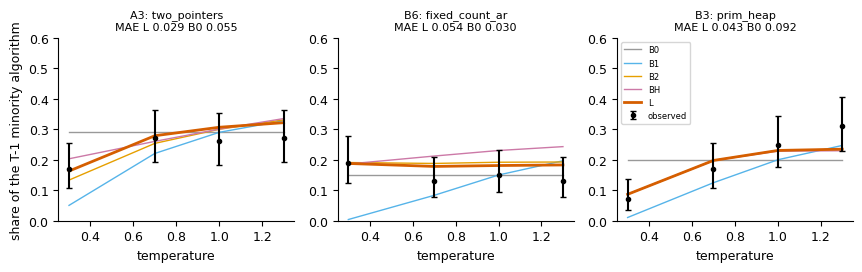

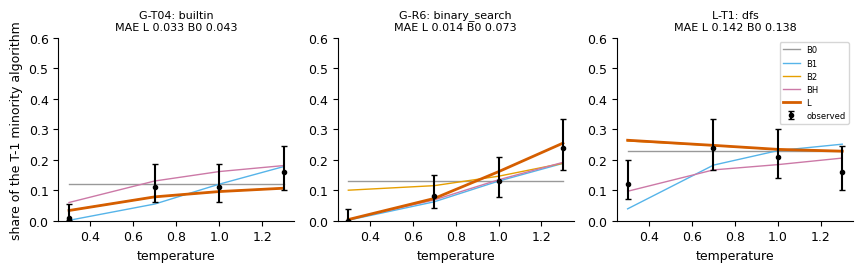

In [27]:
for row in ROWS_OF_3:
    f3({"units": {u: analysis["units"][u] for u in row}})

#### F2: the decision tokens, and how temperature acts on them

**F2** (original) shows the 20 most likely tokens at each blind-located decision position. Bar height is the T-1 probability; colour is $\hat P(\text{minority}\mid\text{token})$; the dashed line is the top-10 cut. In most units the algorithm is decided by one or two tokens with a near-0 / near-1 $\hat P$. Examples:
- B3: `' Kr'` → Kruskal, `' Prim'` → Prim;
- G-T04: `for` → naive scan, `try` → `haystack.index`;
- G-R6: `first` → linear scan (after a second decision), `left`/`low` → binary search.

**Mechanism panel** (notebook-only, under F2). The lines show the tempered probability of the three most likely decision tokens, given that the program has reached the opening. These are the committed teacher-forced `p_top` values, averaged over the five templates. The points show how often the sweep programs that reached the opening actually generated that token. Temperature only flattens or sharpens this one distribution, and that is where the algorithm mix moves.

/tmp/aii_nb_test_envs/art_lzuosbrb34wB-3038de955881/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 24038 (\N{CJK UNIFIED IDEOGRAPH-5DE6}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


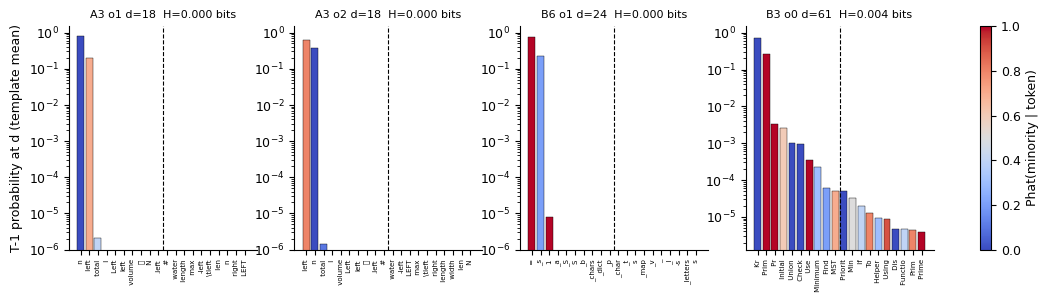

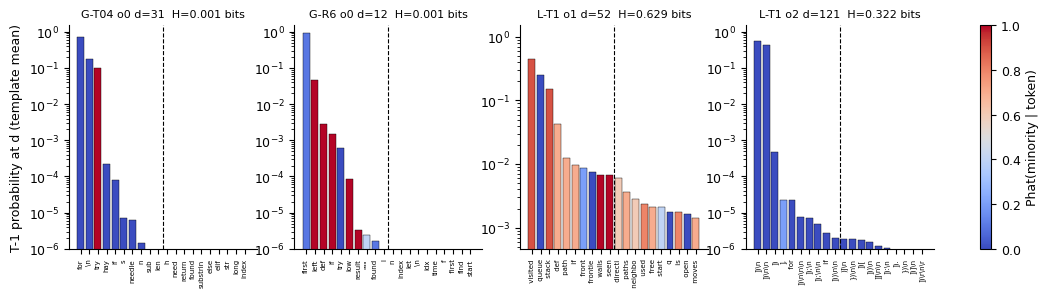

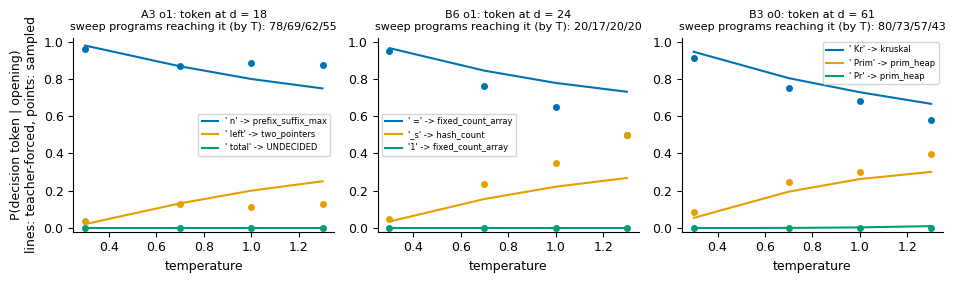

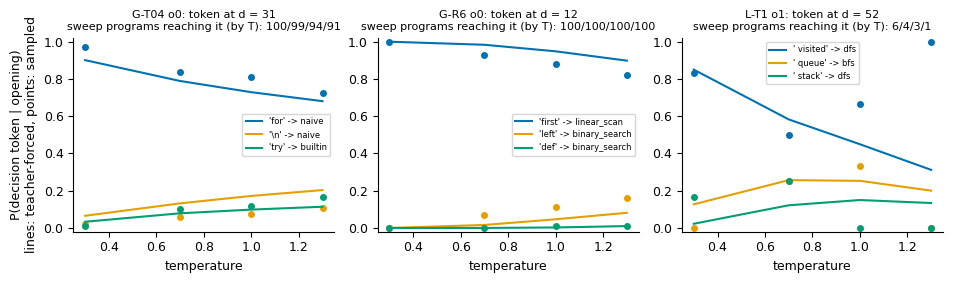

In [28]:
for row in ROWS_OF_3:                # F2 (original), one panel row of units at a time
    FIG_UNITS = row
    f2()

# notebook-only mechanism panel: P_T(decision token | opening), law inputs (lines) vs sweep programs (points)
for row in ROWS_OF_3:
    fig, axs = plt.subplots(1, len(row), figsize=(3.2 * len(row), 2.9), squeeze=False)
    for ax, u in zip(axs[0], row):
        loc, pred = data["units"][u]["locate"], data["units"][u]["predict"]
        o = max(loc["openings"], key=lambda o: sum(loc["on_cover_fit"][o["id"]].values()))
        sweep = [r for r in data["units"][u]["rows"] if r["arm"] == "sweep"]
        reach = {T: [r for r in sweep if abs(r["T"] - T) < 1e-9 and len(r["token_ids"]) > o["d"]
                     and r["token_ids"][:o["d"]] == o["O"]] for T in TEMPS}
        for ci, i in enumerate(np.argsort(o["mass_T1"])[::-1][:3]):
            tok = o["tokens"][i]
            p_law = [np.mean([pred["tf_compact"][w][o["id"]][f"p1|{T}"]["p_top"][i] for w in TEMPLATES]) for T in TEMPS]
            p_obs = [np.mean([r["token_ids"][o["d"]] == tok for r in reach[T]]) if reach[T] else np.nan for T in TEMPS]
            cls = o["classes"]["class_of"].get(str(tok), "?")
            ax.plot(TEMPS, p_law, "-", color=PAL[ci], label=f"{o['token_strs'][i]!r} -> {cls}")
            ax.plot(TEMPS, p_obs, "o", color=PAL[ci], ms=4)
        ax.set_title(f"{u} {o['id']}: token at d = {o['d']}\nsweep programs reaching it (by T): "
                     + "/".join(str(len(reach[T])) for T in TEMPS), fontsize=8)
        ax.set_xlabel("temperature")
        ax.set_ylim(-0.02, 1.02)
        ax.legend(fontsize=6)
    axs[0][0].set_ylabel("P(decision token | opening)\nlines: teacher-forced, points: sampled")
    fig.tight_layout()
    plt.show()

#### F1: how the decision token was found blind (locator curves)

For each stratified base program (one line per base path), the blind locator works as follows:
1. Cut the program after *k* generated tokens.
2. Resample 8 continuations from that prefix at T 1.
3. Record the share of continuations that end up with the same algorithm as the base program.

While the algorithm is still open, the share hovers near the unit's mix. Once the decision token has been passed, it jumps to ~1. The pre-registered Bayesian change-point rule (P ≥ 0.9, TV ≥ 0.25) brackets the jump, and the dotted line marks it. Single-token refinement then pins the exact position, and forced-token confirmation (each of the 20 most likely tokens forced, 10 continuations each) confirms it.

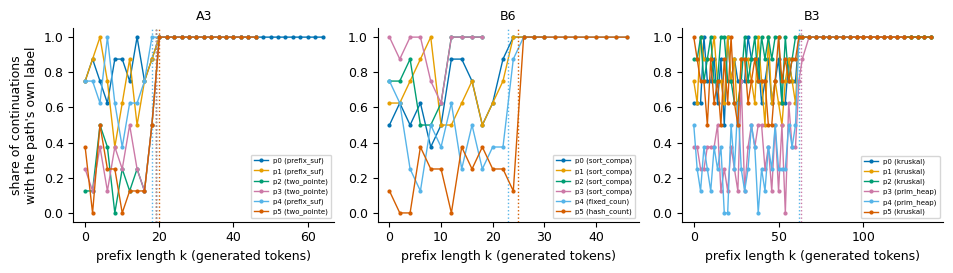

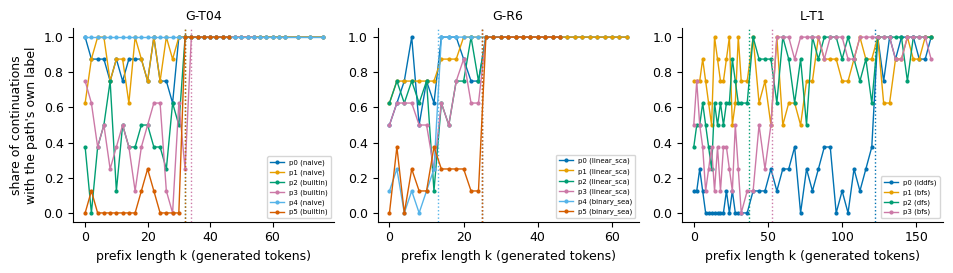

In [29]:
for row in ROWS_OF_3:
    FIG_UNITS = row
    f1()

#### F4: calibration, and F6: per-slot replay

- **F4** plots every (unit, T, label bin) cell's predicted share (law L) against its observed share (N = 100), coloured by model family. Points on the diagonal are calibrated predictions.
- **F6, left**: replay accuracy. For each sweep slot, its own uniforms are walked through the committed openings and decision tokens. Whenever the slot stays on an opening, the committed token classes name an algorithm. The bars show how often that algorithm is the one the program actually wrote (0.87-1.00 on Qwen and Gemma).
- **F6, right**: the realisation gap (observed vs replay-implied) against the mechanism gap (replay-implied vs law). A large realisation gap with a small mechanism gap means the residual error is sampling noise in 100 realised streams, not a wrong mechanism.

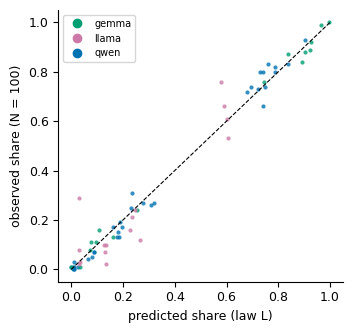

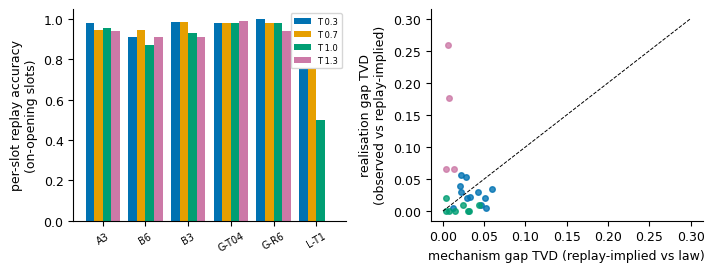

In [30]:
f4(analysis)
f6(analysis)

#### F5: base vs instruct

- **Left**: the decision margin of the instruct model and of the base model on identical token ids.
- **Right**: the mean entropy difference at the 64 phrasing positions. The dashed lines mark the ±0.5-nat bound of the committed prediction.

Post-training sharpened *one* token (gains of 3.27 / 13.41 / 2.11 nats on T1 / T10 / T2) and left phrasing nearly untouched (0.23-0.31 nats). On B3 the base model's own fork distribution would give Prim 0.68, while the instruct model writes Kruskal 0.78. So the instruct model's default algorithm is **not** the base model's "average answer".

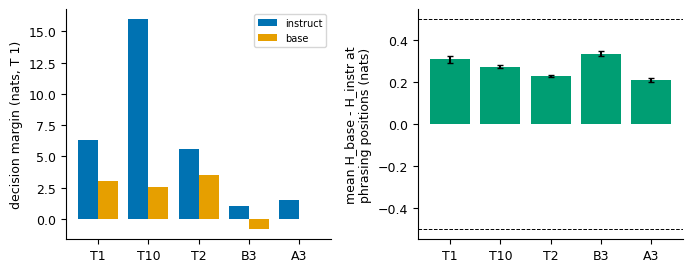

In [31]:
f5()

### Ideas vs phrasings: does a tight temperature give one idea in many phrasings, and does loosening it add ideas?

The scoring counts, per cell and per algorithm ("idea"), how many programs were written and how many **phrasing clusters** they form. Phrasing clusters come from leader clustering of AST node-type 4-gram sets at Jaccard ≥ 0.8, over all programs labelled with a catalogue algorithm.
- **Tight T** (0.3, with top-p 1 or with top-k 10, which is token-identical here): on the Qwen and Gemma units, essentially one idea with one to four phrasing clusters. For example, R6 has 100 linear scans in 2 clusters, B3 has 93 Kruskal in 4 clusters plus 7 Prim in 2, and A3 has 83 prefix/suffix arrays in 1 plus 17 two-pointer programs in 1.
- **Loose T**: no unit gains an idea. Mass moves to the second known idea at the predicted rate, and its phrasings multiply. At T 1.3, B3 has 66 Kruskal in 22 clusters plus 31 Prim in 7, and R6 has 76 linear scans in 2 plus 24 binary searches in 8.
- **Llama T1 is different.** Its long grid-search programs almost all form their own cluster (57-93 clusters). At T 1.3 most of its programs degenerate and no longer parse, so the count collapses.

Across 4,800 programs, temperature re-weights and re-phrases the model's 2-3 known algorithms; it never invents one. The artifact's novelty audit of every correct off-catalogue program (LLM judges, not re-run here) found 0 novel among 4,703 correct programs.

ideas (algorithms)                            programs (phrasing clusters) per idea  total phrasing clusters  correct-only Hill-1
unit  T                                                                                                                                     
A3    0.3                   2                    prefix_suffix_max 83 (1), two_pointers 17 (1)                        2                 1.55
      0.7                   2                    prefix_suffix_max 73 (2), two_pointers 27 (1)                        3                 1.77
      1.0                   2                    prefix_suffix_max 74 (2), two_pointers 26 (2)                        4                 1.75
      1.3                   2                    prefix_suffix_max 72 (3), two_pointers 27 (2)                        5                 1.84
B6    0.3                   3  sort_compare 80 (2), fixed_count_array 19 (1), hash_count 1 (1)                        4                 1.67
      0.7                   3  sort_compare 83 (2), fixed_count_array 13 (2), hash_count 4 (1)                        5                 1.70
      1.0                   3  sort_compare 80 (2), fixed_count_array 15 (3), hash_count 5 (2)                        7                 1.82
      1.3                   3  sort_compare 80 (2), fixed_count_array 13 (4), hash_count 7 (2)                        8                 1.85
B3    0.3                   2                                  kruskal 93 (4), prim_heap 7 (2)                        6                 1.29
      0.7                   2                                 kruskal 82 (9), prim_heap 17 (3)                       12                 1.64
      1.0                   2                                kruskal 74 (13), prim_heap 25 (4)                       17                 1.82
      1.3                   2                                kruskal 66 (22), prim_heap 31 (7)                       29                 2.06
G-T04 0.3                   2                                      naive 99 (1), builtin 1 (1)                        2                 1.04
      0.7                   2                                     naive 89 (1), builtin 11 (1)                        2                 1.41
      1.0                   3                          naive 88 (1), builtin 11 (1), kmp 1 (1)                        3                 1.47
      1.3                   2                                     naive 84 (2), builtin 16 (1)                        3                 1.56
G-R6  0.3                   1                                              linear_scan 100 (2)                        2                 1.00
      0.7                   2                          linear_scan 92 (2), binary_search 8 (3)                        5                 1.30
      1.0                   2                         linear_scan 87 (2), binary_search 13 (4)                        6                 1.46
      1.3                   2                         linear_scan 76 (2), binary_search 24 (8)                       10                 1.68
L-T1  0.3                   3                            bfs 76 (40), dfs 12 (9), iddfs 10 (8)                       57                 1.20
      0.7                   3                            bfs 66 (62), dfs 24 (24), iddfs 7 (7)                       93                 1.37
      1.0                   3                          bfs 61 (61), dfs 21 (21), iddfs 10 (10)                       92                 1.51
      1.3                   3                             bfs 53 (10), dfs 16 (1), iddfs 2 (2)                       13                 1.75

top-k 10 at T 0.3 (the tight-sampling question):


,ideas (algorithms),programs (phrasing clusters) per idea,total phrasing clusters,correct-only Hill-1
unit,,,,
A3,2,"prefix_suffix_max 83 (1), two_pointers 17 (1)",2,1.55
B6,3,"sort_compare 80 (2), fixed_count_array 19 (1), hash_count 1 (1)",4,1.67
B3,2,"kruskal 93 (4), prim_heap 7 (2)",6,1.29
G-T04,2,"naive 99 (1), builtin 1 (1)",2,1.04
G-R6,1,linear_scan 100 (2),2,1.00
L-T1,3,"bfs 76 (40), dfs 12 (9), iddfs 10 (8)",57,1.20


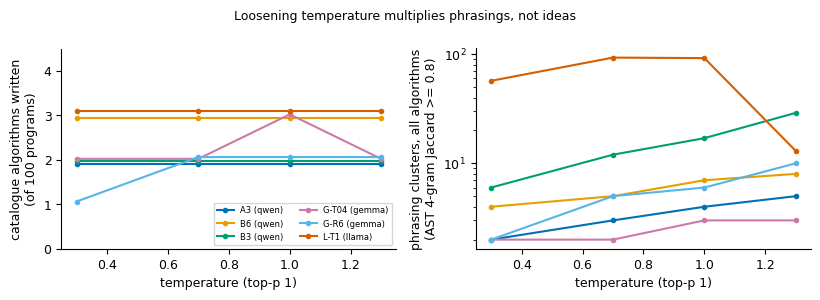

In [32]:
ph_rows = []
for u, a in analysis["units"].items():
    for sname in ("p1", "k10"):
        for T in TEMPS:
            div = a["phrasing"][f"{sname}|{T}"]
            algs = sorted(div.items(), key=lambda kv: -kv[1]["n"])
            ph_rows.append({"unit": u, "sampler": "top-p 1" if sname == "p1" else "top-k 10", "T": T,
                            "ideas (algorithms)": len(algs),
                            "programs (phrasing clusters) per idea": ", ".join(
                                f"{k} {x['n']} ({x['phrasing_clusters_j08']})" for k, x in algs),
                            "total phrasing clusters": sum(x["phrasing_clusters_j08"] for _, x in algs),
                            "correct-only Hill-1": round(a["cells"][f"{sname}|{T}"]["hill1_correct"]["hill1"] or 0, 2)})
ph = pd.DataFrame(ph_rows)
display(ph[ph["sampler"] == "top-p 1"].set_index(["unit", "T"]).drop(columns="sampler"))
print("top-k 10 at T 0.3 (the tight-sampling question):")
display(ph[(ph["sampler"] == "top-k 10") & (ph["T"] == 0.3)].set_index("unit").drop(columns=["sampler", "T"]))

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.0))
for i, u in enumerate(analysis["units"]):
    d = ph[(ph["unit"] == u) & (ph["sampler"] == "top-p 1")]
    jit = (i - 2.5) * 0.04                                   # small vertical offset so equal counts stay visible
    axs[0].plot(d["T"], d["ideas (algorithms)"] + jit, "-o", ms=3, color=PAL[i], label=f"{u} ({UNITS[u]['family']})")
    axs[1].plot(d["T"], d["total phrasing clusters"], "-o", ms=3, color=PAL[i], label=u)
axs[0].set_ylabel("catalogue algorithms written\n(of 100 programs)")
axs[1].set_ylabel("phrasing clusters, all algorithms\n(AST 4-gram Jaccard >= 0.8)")
axs[1].set_yscale("log")
for ax in axs:
    ax.set_xlabel("temperature (top-p 1)")
axs[0].set_ylim(0, 4.5)
axs[0].legend(fontsize=6, ncol=2, loc="lower right")
fig.suptitle("Loosening temperature multiplies phrasings, not ideas", fontsize=9)
fig.tight_layout()
plt.show()

### Summary of this run

This collects every check the notebook made against the committed artifact, plus the headline answer.

**Scope.**
- The decision tokens are a *behavioural* decision point, found by resampling. They say where in the token stream the algorithm becomes fixed, not which model components compute it.
- The outcome is the algorithm a program *attempts*, as named by frozen labellers. Llama's labels are noisy.
- There are six scored units in three families. The held-out evidence rests on two Gemma units.

In [33]:
law_diff = max(max(abs(a - b) for key in data["units"][u]["predict"]["cells"] for m in ("L", "B0", "B1", "B2", "BH")
                   for a, b in zip(recomputed[u]["cells"][key][m], data["units"][u]["predict"]["cells"][key][m]))
               for u in recomputed)
summary = {
    "units re-run": UNITS_TO_RUN,
    "replicate counts": "original" if ORIGINAL_COUNTS else "reduced (stochastic checks skipped)",
    "law unit tests U5/U8-U11 pass": unit_tests["all_pass"],
    "law modules byte-identical to committed code": all(
        hashlib.sha256(Path("demo_src", f).read_bytes()).hexdigest() == committed_code[f]
        for f in ("replay.py", "predict.py", "predict8.py")),
    "committed predictions recomputed, max |diff|": f"{law_diff:.1e}",
    "hash chain of 13 commitments verified": chain_res["ok"],
    "analysis_L values vs committed: mismatches": len(all_mismatches),
    "audit/rederive.py mismatches": rederive["n_mismatches"],
    "base-arm decision values vs committed: mismatches": n_bad,
    "claim L verdict (this run)": analysis["verdict"]["status"],
    "claim L verdict (committed)": data["reference"]["verdict"]["status"],
    "runtime after config cell (s)": round(time.time() - T_START, 1),
}
for k, val in summary.items():
    print(f"{k:<50} {val}")
print("\nMAE of the law per unit (this run):", {u: round(a["mae"]["p1"]["L"], 3) for u, a in analysis["units"].items()})
vd = analysis["verdict"]
print(f"Answer: temperature is not an idea knob. It re-weights the 2-3 algorithms the model already uses, through one "
      f"or two decision tokens, at a rate the frozen law predicted in advance on {vd['n_pass']} of {vd['n_scored']} "
      f"unit(s) re-scored here (artifact: 5 of 6), and it never added an algorithm.")

units re-run                                       ['A3', 'B6', 'B3', 'G-T04', 'G-R6', 'L-T1']
replicate counts                                   original
law unit tests U5/U8-U11 pass                      True
law modules byte-identical to committed code       True
committed predictions recomputed, max |diff|       1.1e-16
hash chain of 13 commitments verified              True
analysis_L values vs committed: mismatches         0
audit/rederive.py mismatches                       0
base-arm decision values vs committed: mismatches  0
claim L verdict (this run)                         PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)
claim L verdict (committed)                        PARTIAL (held-out criterion underpowered: fewer than 4 held-out units scored)
runtime after config cell (s)                      8.4

MAE of the law per unit (this run): {'A3': 0.029, 'B6': 0.054, 'B3': 0.043, 'G-T04': 0.033, 'G-R6': 0.014, 'L-T1': 0.142}
Answer: temperature is 